# Bits Saved: Compression-Progress Curiosity for LLM Agents
### A self-contained experimental notebook (theory → toy → LLM evidence)

This notebook produces everything needed for a paper that operationalizes Schmidhuber's *Driven by Compression Progress* (arXiv:0812.4360) for language-model agents.

**Thesis.** An agent choosing what to read, test or remember should not maximize *surprise* (perplexity, novelty) or *apparent relevance*. It should maximize **compression progress**: the number of bits an item saves when the agent re-encodes the evidence it already holds, minus the bits it costs to take the item in. Because an LLM's negative log-likelihood *is* a code length, this is directly computable.

| Part | What it gives the paper | Needs GPU? |
|---|---|---|
| **1. Theory** | Definitions, five propositions, numerical verification with an exact Bayesian coder | no |
| **2. Toy world** | The classic "noisy-TV" result, boredom, and an inverted-U of interestingness, with exact coders | no |
| **3. LLM experiments** | E1 ranking fidelity · E2 reading agent (fixed reads, and E2b token budget) · E3 boredom · E4 noise dose-response · E5 observer dependence and education · E6 weight-level CP · E7 amortized CP · E8 ablations and the boundedness certificate · E9 no-gazetteer ablation | yes (T4 is enough) |
| **4. Report** | Figures (PDF+PNG), LaTeX tables, `results.json`, an auto-written `paper_summary.md`, and **`paper_inputs/`**: every number, table and figure the LaTeX paper prints, plus `prose_checks.txt`, which tests each qualitative statement in the paper's text against this run | no |

**How to run.** Runtime → *Change runtime type* → **T4 GPU** (or better) → *Run all*.
`MODE="FAST"` takes about 20–30 min on a T4 and is good for drafting. `MODE="FULL"` takes about 2–3 h on a T4 and is what you cite in the paper. On a GPU with more than 22 GB (A100, L4) FULL mode also scores a 7B observer.

**From notebook to paper.** The paper's `main.tex` contains no hand-typed results. After a FULL run, unzip `cp_results.zip`, copy its `paper_inputs` folder next to `main.tex`, and recompile. If `prose_checks.txt` lists a FAIL, the paper prints a draft note naming the sentence to revise.
Everything (synthetic worlds, baselines, evaluation) is generated inside the notebook. No datasets, no API keys. Models are downloaded from the Hugging Face Hub (Qwen2.5 Instruct, ungated).

In [ ]:
# ---- 0.1  Install (Colab already has torch / transformers) ----
import sys, subprocess, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "peft>=0.11", "accelerate"], check=False)
    # Colab's preinstalled torchao is too old for recent peft (ImportError in E6); this notebook doesn't need it.
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-q", "-y", "torchao"], check=False)

In [ ]:
# ---- 0.2  Configuration: the only cell you normally edit ----
MODE = os.environ.get("CP_MODE", "FULL")      # "FAST" | "FULL" | "TEST" (TEST = CPU smoke test with a stand-in scorer)
SAVE_TO_DRIVE = True                         # True: also copy results to Google Drive
SEED = 0

CONFIGS = {
    "TEST": dict(main_model="MOCK", observers=["MOCK-small", "MOCK"], n_worlds=6, n_worlds_agent=3, agent_steps=3,
                 n_worlds_observer=4, run_weight_level=False, n_worlds_weight=0, toy_seeds=6, toy_steps=120,
                 judge=True, max_batch_tokens=4000),
    "FAST": dict(main_model="Qwen/Qwen2.5-1.5B-Instruct",
                 observers=["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"],
                 n_worlds=16, n_worlds_agent=6, agent_steps=4, n_worlds_observer=10,
                 run_weight_level=True, n_worlds_weight=4, toy_seeds=20, toy_steps=300,
                 judge=True, max_batch_tokens=12000),
    "FULL": dict(main_model="Qwen/Qwen2.5-1.5B-Instruct",
                 observers=["Qwen/Qwen2.5-0.5B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"],
                 n_worlds=48, n_worlds_agent=20, agent_steps=5, n_worlds_observer=24,
                 run_weight_level=True, n_worlds_weight=8, toy_seeds=50, toy_steps=400,
                 judge=True, max_batch_tokens=12000),
}
CFG = dict(CONFIGS[MODE])
CFG["weight_model"] = "Qwen/Qwen2.5-0.5B-Instruct" if MODE != "TEST" else "MOCK"
CFG["lambdas"] = [0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0]   # cost weights explored (lambda=1 is strict two-part MDL)
CFG["agent_budget_x"] = 1.5      # E2b: token budget, as a multiple of the full field guide's length in that world
CFG["world_set"] = 0            # 0 = the worlds reported in the paper; 1, 2, ... draw independent sets for replication runs
CFG["gazetteer"] = True          # background vocabulary in memory (see Part 3); False reproduces the lexical-priming ablation
CFG["dev_frac"] = 0.3            # fraction of worlds used only to pick lambda; everything reported is on the rest
CFG["n_boot"] = 2000

RESULTS_DIR = os.path.abspath(os.environ.get("CP_RESULTS", "cp_results"))
FIG_DIR = os.path.join(RESULTS_DIR, "figures"); TAB_DIR = os.path.join(RESULTS_DIR, "tables")
for d in (RESULTS_DIR, FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)
print("MODE:", MODE, "| results ->", RESULTS_DIR)
for k, v in CFG.items(): print(f"  {k}: {v}")

MODE: FULL | results -> /content/cp_results
  main_model: Qwen/Qwen2.5-1.5B-Instruct
  observers: ['Qwen/Qwen2.5-0.5B-Instruct', 'Qwen/Qwen2.5-1.5B-Instruct', 'Qwen/Qwen2.5-3B-Instruct']
  n_worlds: 48
  n_worlds_agent: 20
  agent_steps: 5
  n_worlds_observer: 24
  run_weight_level: True
  n_worlds_weight: 8
  toy_seeds: 50
  toy_steps: 400
  judge: True
  max_batch_tokens: 12000
  weight_model: Qwen/Qwen2.5-0.5B-Instruct
  lambdas: [0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0]
  agent_budget_x: 1.5
  world_set: 0
  gazetteer: True
  dev_frac: 0.3
  n_boot: 2000


In [ ]:
# ---- 0.3  Imports, seeding, plotting style, result registry ----
import json, math, time, random, re, gc, itertools, copy, hashlib, warnings
from collections import defaultdict, Counter
import numpy as np, pandas as pd
import matplotlib
if not IN_COLAB and MODE == "TEST": matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

def seed_all(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s)
    except ImportError: pass
seed_all(SEED)

# Fixed colour per entity (never by rank). Categorical palette validated for CVD; greys for reference lines.
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
           magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948", grey="#8a8985", ink="#0b0b0b")
SIG_STYLE = {   # signal -> (label, colour, linestyle)
    "CP":        ("CP$_\\lambda$ (ours)",          PAL["blue"],    "-"),
    "CP_ratio":  ("Gain per bit $G/S$ (ours)",               PAL["violet"],  "-"),
    "IG_full":   ("Unsealed gain",           PAL["aqua"],    "--"),
    "surprise":  ("Surprise",         PAL["orange"],  "-"),
    "low_ppl":   ("Low perplexity",                PAL["red"],     ":"),
    "novelty":   ("Embedding novelty",             PAL["green"],   "-."),
    "relevance": ("Embedding relevance",     PAL["yellow"],  "-"),
    "judge":     ("LLM judge",                     PAL["magenta"], "-"),
    "random":    ("Random",                        PAL["grey"],    ":"),
    "oracle":    ("Oracle (true utility)",         PAL["ink"],     "--"),
}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 9.5, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8985",
                     "lines.linewidth": 2.0, "legend.frameon": False, "font.family": "DejaVu Sans"})

RESULTS = {"mode": MODE, "config": CFG, "claims": {}}
def savefig(fig, name):
    fig.tight_layout()
    for ext in ("pdf", "png"): fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), bbox_inches="tight")
    plt.show() if IN_COLAB else plt.close(fig)

def to_latex(df, name, caption, float_fmt="{:.3f}"):
    """Minimal booktabs LaTeX writer (no jinja2 dependency). Also writes CSV."""
    df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"))
    cols = [str(c) for c in df.columns]
    lines = ["\\begin{table}[t]\\centering\\small", f"\\caption{{{caption}}}\\label{{tab:{name}}}",
             "\\begin{tabular}{l" + "r" * len(cols) + "}", "\\toprule",
             " & ".join([str(df.index.name or "")] + cols).replace("_", "\\_") + " \\\\", "\\midrule"]
    for idx, row in df.iterrows():
        cells = [str(idx)] + [(float_fmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)) for v in row]
        lines.append(" & ".join(c.replace("_", "\\_").replace("%", "\\%") for c in cells) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    with open(os.path.join(TAB_DIR, f"{name}.tex"), "w") as f: f.write("\n".join(lines))
    return df

def claim(key, statement, supported, evidence):
    """Register a paper claim with the evidence that supports (or refutes) it."""
    RESULTS["claims"][key] = dict(statement=statement, supported=bool(supported), evidence=evidence)
    print(("✔ SUPPORTED   " if supported else "✘ NOT SUPPORTED   ") + statement + "\n      " + evidence)

def boot_ci(x, n=None, alpha=0.05, rng=None):
    x = np.asarray([v for v in x if np.isfinite(v)], float)
    if len(x) == 0: return (np.nan, np.nan, np.nan)
    rng = rng or np.random.default_rng(0); n = n or CFG["n_boot"]
    bs = rng.choice(x, size=(n, len(x)), replace=True).mean(1)
    return (x.mean(), np.quantile(bs, alpha / 2), np.quantile(bs, 1 - alpha / 2))

def wilcoxon_p(a, b):
    """Paired two-sided Wilcoxon signed-rank p-value; NaN when undefined (too few pairs or all differences zero)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    try: return float(stats.wilcoxon(a, b).pvalue) if len(a) >= 5 and not np.allclose(a, b) else np.nan
    except ValueError: return np.nan

def fmt_ci(t, p=3): return f"{t[0]:.{p}f} [{t[1]:.{p}f}, {t[2]:.{p}f}]"
T0 = time.time()

---
# Part 1 — Theory

**Setting.** An observer is a *coder* $q$: for any string $x$ and context $c$, its code length is $L(x\mid c)=-\log_2 q(x\mid c)$ bits. For an LLM, $q$ is the model and the context is its prompt. The agent holds a **memory** $M$ (documents it chose to keep) and a **history** $h$ (evidence it has observed). It considers a candidate item $D$ (a document, tool result, experiment outcome).

We split the history into an *exposed* part $h_{\text{exp}}$, which the outside world may have seen (it is what the agent searches with), and a **sealed audit** $h_{\text{aud}}$, which is never exposed. Everything is conditioned on the observer's current context $C=(M,h_{\text{exp}})$:

| Quantity | Definition | Schmidhuber analogue |
|---|---|---|
| Surprise (reading cost) | $S(D)=L(D\mid C)$ | 1990 prediction-error curiosity; Shannon/Boltzmann surprise (rejected in §2.6) |
| Sealed gain | $G(D)=L(h_{\text{aud}}\mid C)-L(h_{\text{aud}}\mid C,D)$ | eq. (5), $f(a,b)=a-b$: old vs new compressor **on the same data**, scored only where $D$ could not have copied |
| **Compression progress** | $\mathrm{CP}_\lambda(D)=G(D)-\lambda\,S(D)$ | eq. (4)–(5): progress net of the description-length cost |
| Progress ratio | $G(D)/S(D)$ | bits saved per bit read (budgeted agents) |
| Unsealed gain (baseline) | $G_{\text{full}}(D)=L(h\mid M)-L(h\mid M,D)$ | the same, scored on the whole history |

$\lambda$ sets the exchange rate between bits read and bits saved. $\lambda=1$ is strict two-part MDL on the current evidence. $\lambda<1$ amortizes the cost of $D$ over about $1/\lambda$ future re-uses. In the LLM experiments one forward pass over $C\oplus D\oplus h_{\text{aud}}$ yields $S$, $G$ and $\mathrm{CP}_\lambda$ exactly as defined.

### Propositions
**P1 (MDL identity).** For an autoregressive coder with $D$ placed between $C$ and $h_{\text{aud}}$: $\ \mathrm{CP}_1(D)=L(h_{\text{aud}}\mid C)-L(D\oplus h_{\text{aud}}\mid C)$.
*Proof.* Chain rule: $L(D\oplus h_{\text{aud}}\mid C)=L(D\mid C)+L(h_{\text{aud}}\mid C,D)$. $\square$

**P2 (gain is mutual information).** If $q$ is *coherent* (its predictions are marginals of one joint $q(D,h_{\text{aud}}\mid C)$), then $G(D)=\log_2\frac{q(D,h_{\text{aud}}\mid C)}{q(D\mid C)\,q(h_{\text{aud}}\mid C)}$ and $\mathbb E_q[G]=I_q(D;h_{\text{aud}}\mid C)\ge 0$. $\square$
*Reading.* Surprise is self-information; progress is information **shared with sealed evidence**. A negative $G$ (a confident but wrong rule) is evidence *against* $D$.

**P3 (boundedness certificate).** For a coherent coder, $\mathrm{CP}_1(D)=\log_2 q(D\mid C,h_{\text{aud}})\le 0$ for every $D$ and every audit length.
*Proof.* $\mathrm{CP}_1=G-S=\log q(h_{\text{aud}}\mid C,D)-\log q(h_{\text{aud}}\mid C)+\log q(D\mid C)=\log q(D\mid C,h_{\text{aud}})$. $\square$
*Reading.* The cost must be conditioned on the same context as the gain; with $S=L(D\mid M)$ instead, a coherent coder *can* exceed zero. Within this coding setup, $\mathrm{CP}_1>0$ certifies a violation of joint coherence, which we read as evidence of a computationally bounded observer.

**P4 (boredom).** If $D$ is deterministically implied by $C$ under $q$ ($q(D\mid C)=1$), then $S=0$ and $G=0$, so $\mathrm{CP}_\lambda=0$. (For a real LLM, re-reading gives near-zero, not exactly zero, progress.)

**P5 (noisy TV).** (a) $\mathbb E_p[L(D)]=H(p)+\mathrm{KL}(p\Vert q)\ge H(p)$; for fixed finite support, uniform noise maximizes the irreducible part $H(p)$, so for a matched coder expected surprise is maximized by noise, and surprise objectives keep rewarding incompressible data. (b) If $D\perp h_{\text{aud}}\mid C$ under $q$ (for instance any copy or rearrangement of $h_{\text{exp}}$), then $G=0$ and $\mathrm{CP}_\lambda=-\lambda S\le 0$, strictly negative when $\lambda>0$ and $S>0$. The unsealed $G_{\text{full}}$ of such a copy can still be large (the *echo* attack).

**P6 (non-farmability).** For **any** sequence of memory states $M_0,\dots,M_T$, including forgetting, the signed per-step rewards $R_t=L(h_{\text{aud}}\mid M_{t-1},h_{\text{exp}})-L(h_{\text{aud}}\mid M_t,h_{\text{exp}})$ telescope: $\sum_t R_t=L(h_{\text{aud}}\mid M_0,h_{\text{exp}})-L(h_{\text{aud}}\mid M_T,h_{\text{exp}})$. Relearning is paid for by the negative reward of forgetting, and a closed cycle earns exactly zero (cf. arXiv:2606.11417).

Below, every proposition is checked numerically with an **exact coherent Bayesian coder**: a Dirichlet–Markov (KT) mixture over sequences that share an unknown transition matrix. P3 is also contrasted with a deliberately *incoherent* "teachable" coder that weights evidence in its context more heavily than the same evidence in the stream, as in-context learners do.

In [ ]:
# ---- 1.1  Exact coherent Bayesian coder over a set of sequences (Dirichlet-Markov, KT prior) ----
from scipy.special import gammaln, digamma
LOG2E = 1 / np.log(2)

class DirichletMarkovCoder:
    """Coherent Bayesian mixture code. All sequences share one unknown transition matrix theta ~ Dir(alpha) per row.
    Sequences are exchangeable: coding [D, h] jointly equals -log2 of the marginal q(D, h).
    doc_weight > 1 makes it an *incoherent* 'teachable' coder: context documents update counts w-fold."""
    def __init__(self, A, alpha=0.5, doc_weight=1.0):
        self.A, self.alpha, self.w = A, alpha, doc_weight
        self.N = np.zeros((A, A)); self.N0 = np.zeros(A)       # transition counts, initial-state counts
    def copy(self):
        c = DirichletMarkovCoder(self.A, self.alpha, self.w); c.N = self.N.copy(); c.N0 = self.N0.copy(); return c
    def code(self, seq, update=True, weight=1.0):
        """Sequential (prequential) code length of one sequence in bits; optionally absorb it."""
        N, N0, A, a = (self.N if update else self.N.copy()), (self.N0 if update else self.N0.copy()), self.A, self.alpha
        bits = -np.log2((N0[seq[0]] + a) / (N0.sum() + A * a)); N0[seq[0]] += weight
        for x, y in zip(seq[:-1], seq[1:]):
            bits -= np.log2((N[x, y] + a) / (N[x].sum() + A * a)); N[x, y] += weight
        return bits
    def absorb_doc(self, seq):   # memory/context document: coded normally, then absorbed at weight w (w=1 -> coherent)
        bits = self.code(seq, update=True, weight=1.0)
        if self.w != 1.0:
            self.N0[seq[0]] += self.w - 1
            np.add.at(self.N, (seq[:-1], seq[1:]), self.w - 1)
        return bits

def sample_chain(P, n, rng, x0=None):
    A = len(P); x = [rng.integers(A) if x0 is None else x0]
    for _ in range(n - 1): x.append(rng.choice(A, p=P[x[-1]]))
    return np.array(x)

def random_chain(A, eta, rng):
    """Each row: mass (1-eta) on one successor (a random permutation) + eta spread uniformly."""
    perm = rng.permutation(A); P = np.full((A, A), eta / A)
    P[np.arange(A), perm] += 1 - eta
    return P

def cp_terms(coder_factory, M_docs, h_exp, h_aud, D):
    """Returns S, G_full, G_seal for candidate D given memory docs, exactly (fresh coder per condition)."""
    def run(with_D):
        c = coder_factory()
        for m in M_docs: c.absorb_doc(m)
        S = c.absorb_doc(D) if with_D else 0.0
        b_exp = c.code(h_exp); b_aud = c.code(h_aud)
        return S, b_exp, b_aud
    _, e0, a0 = run(False); S, e1, a1 = run(True)
    c = coder_factory()                                  # sealed order: C = (M, h_exp), then D, then h_aud
    for m in M_docs: c.absorb_doc(m)
    c.code(h_exp); S_seal = c.absorb_doc(D); a2 = c.code(h_aud)
    return dict(S=S, G_full=(e0 + a0) - (e1 + a1), G_seal=a0 - a1, CP1_full=(e0 + a0) - (S + e1 + a1),
                S_seal=S_seal, CP1_seal=a0 - (S_seal + a2))

In [ ]:
# ---- 1.2  Numerical verification of P1–P6 ----
rng = np.random.default_rng(SEED)
A, n_h, n_d = 8, 60, 60
rows = []
for trial in range(400 if MODE != "TEST" else 60):
    P = random_chain(A, 0.15, rng); P_other = random_chain(A, 0.15, rng)
    h_exp, h_aud = sample_chain(P, n_h, rng), sample_chain(P, n_h, rng)
    perm_cycle = np.array([0] + [int(np.argmax(P[i])) for i in range(A)])     # a compact 'rule': follow each state's likeliest successor
    walk = [0]
    for _ in range(A): walk.append(int(np.argmax(P[walk[-1]])))
    docs = {"EXAMPLES (same source)": sample_chain(P, n_d, rng),
            "NOISE (uniform iid)": rng.integers(A, size=n_d),
            "ECHO (copy of h_exp)": h_exp.copy(),
            "OTHER source": sample_chain(P_other, n_d, rng),
            "RULE-walk (compact)": np.array(walk)}
    for name, D in docs.items():
        for coder_name, w in (("coherent", 1.0), ("teachable w=8", 8.0)):
            t = cp_terms(lambda: DirichletMarkovCoder(A, 0.5, w), [], h_exp, h_aud, D)
            rows.append(dict(trial=trial, doc=name, coder=coder_name, **t))
toy_props = pd.DataFrame(rows)

# P2 exactly: sample (D, h) from the coder's OWN prior predictive -> E[G] = I(D;h) >= 0
g_prior = []
for _ in range(400 if MODE != "TEST" else 60):
    P = np.vstack([rng.dirichlet(np.full(A, 0.5)) for _ in range(A)]); pi0 = rng.dirichlet(np.full(A, 0.5))   # the coder's prior: rows and initial-state distribution
    D, h = sample_chain(P, 40, rng, x0=rng.choice(A, p=pi0)), sample_chain(P, 40, rng, x0=rng.choice(A, p=pi0))
    c0 = DirichletMarkovCoder(A); b0 = c0.code(h)
    c1 = DirichletMarkovCoder(A); c1.code(D); b1 = c1.code(h)
    g_prior.append(b0 - b1)
g_prior = np.array(g_prior)

# P6 telescoping: sequential sealed gains over a stream of acquisitions sum to endpoint improvement
P = random_chain(A, 0.15, rng); h_exp, h_aud = sample_chain(P, n_h, rng), sample_chain(P, n_h, rng)
acq = [sample_chain(P, 30, rng) for _ in range(6)] + [rng.integers(A, size=30)]
M, seq_gains = [], []
for D in acq:
    seq_gains.append(cp_terms(lambda: DirichletMarkovCoder(A), M, h_exp, h_aud, D)["G_seal"]); M = M + [D]
def aud_bits(Ms):
    c = DirichletMarkovCoder(A)
    for m in Ms: c.absorb_doc(m)
    c.code(h_exp); return c.code(h_aud)
telescope_err = abs(sum(seq_gains) - (aud_bits([]) - aud_bits(acq)))

toy_props["CP1_mixed"] = toy_props.G_seal - toy_props.S      # sealed gain minus a cost NOT conditioned on h_exp (inconsistent)
summ = toy_props.groupby(["coder", "doc"]).agg(S=("S", "mean"), G_full=("G_full", "mean"), G_seal=("G_seal", "mean"),
                                               CP1=("CP1_full", "mean"), CP1_seal=("CP1_seal", "mean"),
                                               frac_CP1_pos=("CP1_full", lambda x: (x > 1e-9).mean()),
                                               frac_CP1_seal_pos=("CP1_seal", lambda x: (x > 1e-9).mean()),
                                               frac_mixed_pos=("CP1_mixed", lambda x: (x > 1e-9).mean()))
coh = summ.loc["coherent"]
tab = coh.copy(); tab.index.name = "Document (coherent coder)"
to_latex(tab.round(2), "toy_propositions", "Exact Bayesian coder: mean surprise $S$, unsealed gain, sealed gain, and MDL progress CP$_1$ (bits). P3: CP$_1\\le 0$ always.")
print(tab.round(2).to_string())
print("\nTeachable (incoherent) coder:\n", summ.loc["teachable w=8"].round(2).to_string())

max_cp1_coh = toy_props.query("coder=='coherent'")[["CP1_full", "CP1_seal"]].max().max()
surp_rank = coh.S.sort_values(ascending=False).index[0]
cp_rank_last = (coh.G_seal - 0.1 * coh.S).sort_values().index[0]
RESULTS["theory"] = dict(max_CP1_coherent=float(max_cp1_coh), EG_prior_mean=float(g_prior.mean()),
                         EG_prior_ci=boot_ci(g_prior), telescope_abs_err=float(telescope_err),
                         teachable_frac_CP1_pos=summ.loc["teachable w=8"].frac_CP1_pos.to_dict())
claim("P2", "Under the coder's own joint, expected gain equals mutual information and is non-negative",
      boot_ci(g_prior)[1] > -1e-9 or g_prior.mean() >= 0, f"E[G] = {fmt_ci(boot_ci(g_prior), 2)} bits over {len(g_prior)} prior-predictive draws")
claim("P3", "A coherent Bayesian coder never has positive MDL progress (CP_1 <= 0 for every document)",
      max_cp1_coh <= 1e-6, f"max CP_1 (sealed and unsealed forms) over {int((toy_props.coder=='coherent').sum())} coherent cases = {max_cp1_coh:.2e} bits; "
      f"teachable coder: CP_1>0 in {100*summ.loc['teachable w=8'].frac_CP1_pos.max():.0f}% of cases for its best doc type")
claim("P5a", "Surprise ranks the noise TV first", "NOISE" in surp_rank, f"top surprise doc type = {surp_rank}")
cp01 = (coh.G_seal - 0.1 * coh.S)
mixed_pos = (toy_props.query("coder=='coherent'").CP1_mixed > 1e-9).mean()
print(f"Conditioning matters: with the cost L(D|M) instead of L(D|M,h_exp), the coherent coder shows 'CP_1>0' in {mixed_pos:.1%} of cases.")
RESULTS["theory"]["coherent_frac_pos_with_unconditioned_cost"] = float(mixed_pos)
claim("P5b", "Compression progress ranks the noise TV below every same-source document",
      all(cp01[k] > cp01["NOISE (uniform iid)"] for k in ["EXAMPLES (same source)", "RULE-walk (compact)", "ECHO (copy of h_exp)"]),
      "CP_0.1 by type: " + ", ".join(f"{k.split(' ')[0]}={v:.1f}" for k, v in cp01.sort_values(ascending=False).items()))
claim("P5c", "Echo documents inflate unsealed gain but not sealed gain",
      coh.loc["ECHO (copy of h_exp)", "G_full"] > 5 * max(abs(coh.loc["ECHO (copy of h_exp)", "G_seal"]), 1),
      f"ECHO: G_full={coh.loc['ECHO (copy of h_exp)','G_full']:.1f} bits vs G_seal={coh.loc['ECHO (copy of h_exp)','G_seal']:.1f} bits")
claim("P6", "Sequential sealed gains telescope to the endpoint audit improvement", telescope_err < 1e-6,
      f"|sum of gains - endpoint difference| = {telescope_err:.1e} bits")

                                S  G_full  G_seal     CP1  CP1_seal  frac_CP1_pos  frac_CP1_seal_pos  frac_mixed_pos
Document (coherent coder)                                                                                           
ECHO (copy of h_exp)       100.60   48.10    2.72  -52.49    -52.49           0.0                0.0             0.0
EXAMPLES (same source)      99.79   35.20    5.83  -64.59    -64.59           0.0                0.0             0.0
NOISE (uniform iid)        192.52  -47.50  -19.49 -240.02   -240.02           0.0                0.0             0.0
OTHER source               102.23  -61.92  -24.02 -164.15   -164.15           0.0                0.0             0.0
RULE-walk (compact)         21.41   13.97    2.12   -7.44     -7.44           0.0                0.0             0.0

Teachable (incoherent) coder:
                              S  G_full  G_seal     CP1  CP1_seal  frac_CP1_pos  frac_CP1_seal_pos  frac_mixed_pos
doc                                

---
# Part 2 — Toy world: the noisy TV, boredom, and the inverted-U (exact coders, CPU)

A curious agent faces seven **channels**. Each step it picks one and watches a chunk of 20 symbols. The first half updates that channel's Bayesian Markov model; the second half goes to a sealed audit buffer (the toy analogue of $h_{\text{aud}}$):

| Channel | Source | Why it's there |
|---|---|---|
| `easy` | 6-symbol, near-deterministic Markov chain | learnable, fast |
| `medium` | 12-symbol, mostly deterministic | learnable, slower |
| `hard` | 20-symbol, mostly deterministic | learnable, slowest |
| `noise TV 1–3` | 8/16/24-symbol **uniform iid** | maximal surprise, nothing to learn |
| `solved` | 4-symbol deterministic cycle the model has **already learned** (2,000 symbols seen) | the fully predictable 'dark room' |

Intrinsic rewards compared (all from the paper's §3 lineage):
* **Surprise** (1990): bits needed to code the new chunk.
* **Compression progress, retrospective** (eq. 6 literally): $C(p_{\text{old}},h)-C(p_{\text{new}},h)$, the old and new model re-scored on the *same stored training history* of that channel.
* **Compression progress, sealed** (ours): the same difference scored on the channel's sealed audit buffer, which the model never trains on.
* **Bayesian surprise / info-gain** (1995): KL(posterior‖prior) of the model parameters.
* **Count novelty**: $1/\sqrt{n+1}$ visits.
* **Random**.

The agent is ε-greedy (ε=0.1) on an exponential moving average of the rewards seen from each channel. We measure the **world-model error** (KL from true to learned transitions, summed over the three learnable channels) and **where the agent's time went**.

In [ ]:
# ---- 2.1  Bandit over channels with exact Bayesian models ----
def dir_kl_rows(a_post, a_prior):
    """Sum over rows of KL(Dir(a_post) || Dir(a_prior))."""
    s_p, s_q = a_post.sum(1), a_prior.sum(1)
    return float(np.sum(gammaln(s_p) - gammaln(s_q) - np.sum(gammaln(a_post) - gammaln(a_prior), 1)
                        + np.sum((a_post - a_prior) * (digamma(a_post) - digamma(s_p)[:, None]), 1))) * LOG2E

class Channel:
    """One observable source plus the agent's Bayesian model of it. Each visit yields a chunk of m symbols:
    the first half trains the model, the second half is appended to a *sealed audit buffer* that is never trained on."""
    def __init__(self, name, P, rng):
        self.name, self.P, self.A = name, P, len(P)
        self.N = np.zeros((self.A, self.A))      # model counts (training data)
        self.T = np.zeros((self.A, self.A))      # transition counts of the stored training history
        self.Aud = np.zeros((self.A, self.A))    # transition counts of the sealed audit buffer
        self.last = int(rng.integers(self.A)); self.visits = 0
    def model(self, N=None, a=0.5):
        N = self.N if N is None else N; return (N + a) / (N.sum(1, keepdims=True) + self.A * a)
    def step(self, m, rng):
        chunk = sample_chain(self.P, m + 1, rng, x0=self.last)[1:]
        prev = np.concatenate([[self.last], chunk[:-1]]); self.last = int(chunk[-1])
        half = m // 2; N_old = self.N.copy(); bits = 0.0
        for x, y in zip(prev[:half], chunk[:half]):           # prequential code of the training half (= surprise)
            bits -= np.log2((self.N[x, y] + 0.5) / (self.N[x].sum() + self.A * 0.5)); self.N[x, y] += 1
        np.add.at(self.T, (prev[:half], chunk[:half]), 1)
        C = lambda counts, Nm: -np.sum(counts * np.log2(self.model(Nm)))
        n_aud = self.Aud.sum()
        cp_seal = (C(self.Aud, N_old) - C(self.Aud, self.N)) / n_aud * half if n_aud else np.inf   # per trained symbol
        cp_retro = C(self.T, N_old) - C(self.T, self.N)        # eq. (6) literally: old vs new model on the stored history
        np.add.at(self.Aud, (prev[half:], chunk[half:]), 1)    # seal the second half
        self.visits += 1
        return dict(surprise=bits / half, cp=cp_seal, cp_retro=cp_retro,
                    infogain=dir_kl_rows(self.N + 0.5, N_old + 0.5), novelty=1 / np.sqrt(self.visits))
    def error(self):
        Q = self.model(); return float(np.mean(np.sum(self.P * np.log2(self.P / Q + 1e-300), 1)))

def make_channels(rng, spec):
    chans = []
    for name, A_, eta, *pre in spec:
        c = Channel(name, random_chain(A_, eta, rng), rng)
        if pre:   # an already-understood source: the model has seen `pre` symbols of it (and the audit a matching amount)
            x = sample_chain(c.P, pre[0] + 1, rng); np.add.at(c.N, (x[:-1], x[1:]), 1); np.add.at(c.T, (x[:-1], x[1:]), 1)
            y = sample_chain(c.P, pre[0] + 1, rng); np.add.at(c.Aud, (y[:-1], y[1:]), 1); c.last = int(x[-1])
        chans.append(c)
    return chans

TOY_SPEC = [("easy", 6, 0.05), ("medium", 12, 0.1), ("hard", 20, 0.1),
            ("noise TV 1", 8, 1.0), ("noise TV 2", 16, 1.0), ("noise TV 3", 24, 1.0), ("solved", 4, 0.0, 2000)]
NOISE_IDX = [3, 4, 5]; SOLVED_IDX = 6
LEARNABLE = ["easy", "medium", "hard"]
TOY_STRATS = ["cp", "cp_retro", "surprise", "infogain", "novelty", "random"]
TOY_LABEL = {"cp": "Compression progress, sealed audit", "cp_retro": "Compression progress, retrospective (eq. 6)",
             "surprise": "Surprise (pred. error)", "infogain": "Bayesian info-gain (KL)", "novelty": "Count novelty", "random": "Random"}
TOY_COLOR = {"cp": PAL["blue"], "cp_retro": PAL["violet"], "surprise": PAL["orange"], "infogain": PAL["aqua"],
             "novelty": PAL["green"], "random": PAL["grey"]}
EMA = 0.3   # the agent's estimate of a channel's future reward: exponential moving average of its rewards (a crude 'predictor of predictor changes', §3.2)

def run_bandit(strategy, spec, steps, seed, m=20, eps=0.1, track=None):
    rng = np.random.default_rng(seed); chans = make_channels(np.random.default_rng(1000 + seed), spec)
    est = np.full(len(chans), np.inf); err, picks, rew_trace = [], [], []
    for t in range(steps):
        if strategy == "random" or rng.random() < eps: k = int(rng.integers(len(chans)))
        elif np.max(est) <= 0: k = int(rng.integers(len(chans)))      # bored of everything -> explore at random
        else: k = int(np.argmax(est + 1e-9 * rng.random(len(chans))))
        sig = chans[k].step(m, rng)
        if strategy != "random":
            r = sig[strategy]
            est[k] = r if not np.isfinite(est[k]) or not np.isfinite(r) else (1 - EMA) * est[k] + EMA * r
        picks.append(k); rew_trace.append((k, sig.get(track or strategy, np.nan)))
        err.append(sum(c.error() for c in chans if c.name in LEARNABLE))
    return np.array(err), np.array(picks), rew_trace

toy_err, toy_share, toy_traces = {}, {}, {}
for s in TOY_STRATS:
    E, S = [], []
    for seed in range(CFG["toy_seeds"]):
        e, p, tr = run_bandit(s, TOY_SPEC, CFG["toy_steps"], seed)
        E.append(e); S.append(np.bincount(p, minlength=len(TOY_SPEC)) / len(p))
        if seed == 0: toy_traces[s] = tr
    toy_err[s], toy_share[s] = np.array(E), np.array(S)

final = {s: boot_ci(toy_err[s][:, -1]) for s in TOY_STRATS}
noise_share = {s: boot_ci(toy_share[s][:, NOISE_IDX].sum(1)) for s in TOY_STRATS}
tab = pd.DataFrame({"final world-model error (bits/sym)": {TOY_LABEL[s]: fmt_ci(final[s], 3) for s in TOY_STRATS},
                    "time on noise TVs": {TOY_LABEL[s]: fmt_ci(noise_share[s], 2) for s in TOY_STRATS},
                    "time on solved channel": {TOY_LABEL[s]: f"{toy_share[s][:, SOLVED_IDX].mean():.2f}" for s in TOY_STRATS}})
tab.index.name = "Intrinsic reward"
to_latex(tab, "toy_bandit", f"Noisy-TV bandit, {CFG['toy_seeds']} seeds × {CFG['toy_steps']} steps. Mean [95\\% bootstrap CI].")
print(tab.to_string())
RESULTS["toy"] = dict(final_error={s: final[s] for s in TOY_STRATS}, noise_share={s: noise_share[s] for s in TOY_STRATS})

                                            final world-model error (bits/sym)  time on noise TVs time on solved channel
Intrinsic reward                                                                                                        
Compression progress, sealed audit                        0.182 [0.171, 0.199]  0.08 [0.07, 0.08]                   0.21
Compression progress, retrospective (eq. 6)               0.391 [0.346, 0.450]  0.60 [0.60, 0.61]                   0.02
Surprise (pred. error)                                    3.048 [2.855, 3.247]  0.93 [0.93, 0.94]                   0.02
Bayesian info-gain (KL)                                   1.425 [1.350, 1.501]  0.87 [0.87, 0.88]                   0.02
Count novelty                                             0.346 [0.336, 0.358]  0.43 [0.43, 0.43]                   0.14
Random                                                    0.356 [0.343, 0.371]  0.43 [0.42, 0.44]                   0.14


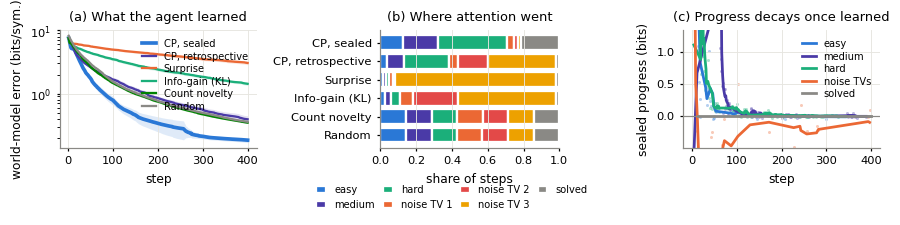

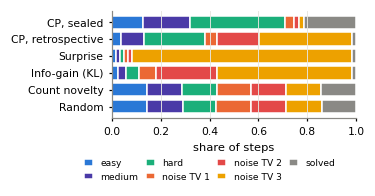

✔ SUPPORTED   Surprise-driven agents get stuck on the noise TV; compression-progress agents do not
      time on noise TV: surprise 0.93 [0.93, 0.94] vs CP 0.08 [0.07, 0.08]
✔ SUPPORTED   Sealing the audit is what protects compression progress from noise: the literal retrospective form (eq. 6) over-fits noise TVs
      time on noise TVs: retrospective 0.60 [0.60, 0.61] vs sealed 0.08 [0.07, 0.08]
✔ SUPPORTED   Sealed compression progress learns the world faster than random or count-based exploration
      final error CP 0.182 vs random 0.356 vs novelty 0.346 (Wilcoxon vs random p=6.6e-13)
✔ SUPPORTED   Compression-progress agents learn the world better than surprise-driven ones
      final error CP 0.182 vs surprise 3.048 bits/sym (Wilcoxon p=1.8e-15)


In [ ]:
# ---- 2.2  Figure 1: learning curves, allocation, boredom ----
fig, ax = plt.subplots(1, 3, figsize=(8.2, 2.3), gridspec_kw=dict(width_ratios=[1.1, 1.0, 1.1]))   # sized for a full-width paper figure
SHORT = {"cp": "CP, sealed", "cp_retro": "CP, retrospective", "surprise": "Surprise", "infogain": "Info-gain (KL)",
         "novelty": "Count novelty", "random": "Random"}
x = np.arange(1, CFG["toy_steps"] + 1)
for s in TOY_STRATS:
    mu = toy_err[s].mean(0); se = toy_err[s].std(0) / np.sqrt(len(toy_err[s]))
    ax[0].plot(x, mu, color=TOY_COLOR[s], label=SHORT[s], lw=2.4 if s == "cp" else 1.5)
    ax[0].fill_between(x, mu - 1.96 * se, mu + 1.96 * se, color=TOY_COLOR[s], alpha=0.15, lw=0)
ax[0].set(yscale="log", xlabel="step", ylabel="world-model error (bits/sym.)", title="(a) What the agent learned")
ax[0].legend(fontsize=6.5, loc="upper right", handlelength=1.4, labelspacing=0.25)
ch_cols = [PAL["blue"], PAL["violet"], PAL["aqua"], PAL["orange"], PAL["red"], PAL["yellow"], PAL["grey"]]  # cool = learnable, warm = noise
left = np.zeros(len(TOY_STRATS))
for j, (name, *_) in enumerate(TOY_SPEC):
    vals = np.array([toy_share[s][:, j].mean() for s in TOY_STRATS])
    ax[1].barh(range(len(TOY_STRATS)), vals, left=left, color=ch_cols[j], edgecolor="white", linewidth=1.5, label=name)
    left += vals
ax[1].set_yticks(range(len(TOY_STRATS))); ax[1].set_yticklabels([SHORT[s] for s in TOY_STRATS]); ax[1].invert_yaxis()
ax[1].set(xlabel="share of steps", title="(b) Where attention went", xlim=(0, 1)); ax[1].grid(axis="y", visible=False)
ax[1].legend(fontsize=6.5, ncol=4, loc="upper center", bbox_to_anchor=(0.4, -0.24), columnspacing=0.8, handlelength=1.0)
tr = toy_traces["cp"]
groups = [("easy", [0], PAL["blue"]), ("medium", [1], PAL["violet"]), ("hard", [2], PAL["aqua"]),
          ("noise TVs", NOISE_IDX, PAL["orange"]), ("solved", [SOLVED_IDX], PAL["grey"])]
for name, idx, col in groups:
    pts = [(t, r) for t, (k, r) in enumerate(tr) if k in idx and np.isfinite(r)]
    if pts:
        t_, r_ = map(np.array, zip(*pts))
        ax[2].scatter(t_, r_, s=4, color=col, alpha=0.35, lw=0)
        sm = pd.Series(r_).rolling(5, min_periods=1).mean().values
        ax[2].plot(t_, sm, color=col, lw=1.8, label=name)
ax[2].axhline(0, color=PAL["grey"], lw=0.8)
lo, hi = np.nanpercentile([r for _, r in tr if np.isfinite(r)], [2, 98])
ax[2].set(ylim=(min(lo, -0.05), hi * 1.1), xlabel="step", ylabel="sealed progress (bits)", title="(c) Progress decays once learned")
for a in ax:
    a.title.set_fontsize(8.5); a.xaxis.label.set_fontsize(8); a.yaxis.label.set_fontsize(8); a.tick_params(labelsize=7.5, length=2)
ax[2].legend(fontsize=6.5, loc="upper right", handlelength=1.4, labelspacing=0.25)
savefig(fig, "fig1_toy_noisy_tv")

# Column-width version of panel (b), used in the paper
fig, ax1 = plt.subplots(figsize=(3.5, 2.05)); left = np.zeros(len(TOY_STRATS))
for j, (name, *_) in enumerate(TOY_SPEC):
    vals = np.array([toy_share[s][:, j].mean() for s in TOY_STRATS])
    ax1.barh(range(len(TOY_STRATS)), vals, left=left, color=ch_cols[j], edgecolor="white", linewidth=1.0, label=name); left += vals
ax1.set_yticks(range(len(TOY_STRATS))); ax1.set_yticklabels([SHORT[s] for s in TOY_STRATS], fontsize=7); ax1.invert_yaxis()
ax1.set_xlim(0, 1); ax1.set_xlabel("share of steps", fontsize=7.5); ax1.tick_params(labelsize=7, length=2); ax1.grid(axis="y", visible=False)
ax1.legend(fontsize=6, ncol=4, loc="upper center", bbox_to_anchor=(0.4, -0.3), columnspacing=0.8, handlelength=1.0)
savefig(fig, "fig1b_toy_allocation")

cp_err, sur_err = toy_err["cp"][:, -1], toy_err["surprise"][:, -1]
claim("toy_noisy_tv", "Surprise-driven agents get stuck on the noise TV; compression-progress agents do not",
      noise_share["surprise"][0] > 0.5 and noise_share["cp"][0] < 0.25,
      f"time on noise TV: surprise {fmt_ci(noise_share['surprise'],2)} vs CP {fmt_ci(noise_share['cp'],2)}")
retro_noise = noise_share["cp_retro"]
claim("toy_sealing", "Sealing the audit is what protects compression progress from noise: the literal retrospective form (eq. 6) over-fits noise TVs",
      retro_noise[0] > 2 * noise_share["cp"][0],
      f"time on noise TVs: retrospective {fmt_ci(retro_noise,2)} vs sealed {fmt_ci(noise_share['cp'],2)}")
rnd_err = toy_err["random"][:, -1]
claim("toy_vs_random", "Sealed compression progress learns the world faster than random or count-based exploration",
      wilcoxon_p(cp_err, rnd_err) < 0.05 and cp_err.mean() < min(rnd_err.mean(), toy_err["novelty"][:, -1].mean()),
      f"final error CP {cp_err.mean():.3f} vs random {rnd_err.mean():.3f} vs novelty {toy_err['novelty'][:, -1].mean():.3f} (Wilcoxon vs random p={wilcoxon_p(cp_err, rnd_err):.1e})")
claim("toy_learning", "Compression-progress agents learn the world better than surprise-driven ones",
      wilcoxon_p(cp_err, sur_err) < 0.05 and cp_err.mean() < sur_err.mean(),
      f"final error CP {cp_err.mean():.3f} vs surprise {sur_err.mean():.3f} bits/sym (Wilcoxon p={wilcoxon_p(cp_err, sur_err):.1e})")

### Inverted-U: interestingness peaks at *learnable-but-not-yet-learned*
§2.11 argues a listener should skip "the one he just heard ten times" and "the new weird one with the completely unfamiliar rhythm" in favour of something "unfamiliar enough … but familiar enough to allow for quickly recognizing … a new learnable regularity". We order six 8-symbol channels along that axis, from **already known** to **pure noise**. Compression progress should trace an inverted U; surprise should rise monotonically.

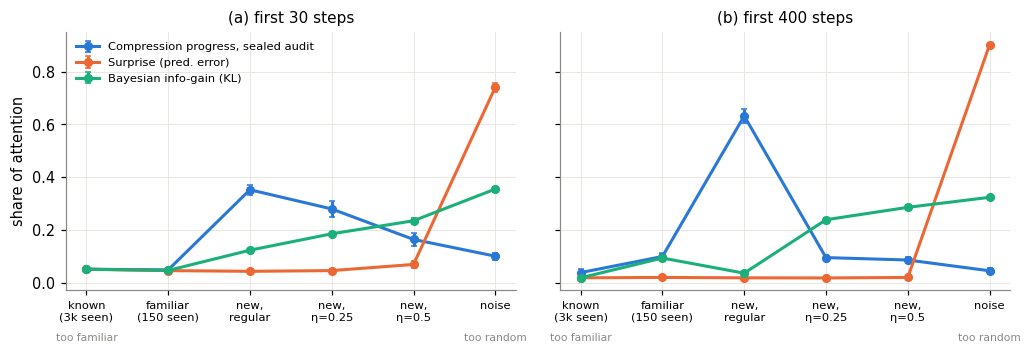

✔ SUPPORTED   Compression progress peaks between 'already known' and 'pure noise' while surprise concentrates on pure noise
      CP attention peaks at 'new, regular' (first 30 steps: [0.05, 0.05, 0.35, 0.28, 0.16, 0.1]); surprise attention (full run): [0.02, 0.02, 0.02, 0.02, 0.02, 0.9]


In [ ]:
# ---- 2.3  Figure 2: allocation vs noise level ----
U_SPEC = [("known\n(3k seen)", 8, 0.0, 3000), ("familiar\n(150 seen)", 8, 0.1, 150), ("new,\nregular", 8, 0.0),
          ("new,\nη=0.25", 8, 0.25), ("new,\nη=0.5", 8, 0.5), ("noise", 8, 1.0)]
U_LABELS = [u[0] for u in U_SPEC]; U_STEPS = [30, CFG["toy_steps"]]
ushare = {}
for s in ["cp", "surprise", "infogain"]:
    for T in U_STEPS:
        ushare[(s, T)] = np.array([np.bincount(run_bandit(s, U_SPEC, T, 100 + seed)[1], minlength=len(U_SPEC)) / T
                                   for seed in range(CFG["toy_seeds"])])
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3), sharey=True)
xs = np.arange(len(U_SPEC))
for i, T in enumerate(U_STEPS):
    for s in ["cp", "surprise", "infogain"]:
        mu = ushare[(s, T)].mean(0); se = ushare[(s, T)].std(0) / np.sqrt(CFG["toy_seeds"])
        ax[i].errorbar(xs, mu, yerr=1.96 * se, color=TOY_COLOR[s], marker="o", ms=5, capsize=2, label=TOY_LABEL[s])
    ax[i].set_xticks(xs); ax[i].set_xticklabels(U_LABELS, fontsize=7.5)
    ax[i].set(title=f"({'ab'[i]}) first {T} steps")
    ax[i].annotate("too familiar", (0, 0), xytext=(0, -38), textcoords="offset points", fontsize=7, color=PAL["grey"], ha="center")
    ax[i].annotate("too random", (5, 0), xytext=(0, -38), textcoords="offset points", fontsize=7, color=PAL["grey"], ha="center")
ax[0].set_ylabel("share of attention"); ax[0].legend(fontsize=7.5, loc="upper left")
savefig(fig, "fig2_toy_inverted_u")
cp_early = ushare[("cp", U_STEPS[0])].mean(0)
peak = int(np.argmax(cp_early))
sur_full = ushare[("surprise", U_STEPS[-1])].mean(0)
RESULTS["toy"]["inverted_u"] = {f"{s}_T{T}": ushare[(s, T)].mean(0).tolist() for (s, T) in ushare}
claim("toy_inverted_u", "Compression progress peaks between 'already known' and 'pure noise' while surprise concentrates on pure noise",
      0 < peak < len(U_SPEC) - 1 and cp_early[peak] > cp_early[0] and cp_early[peak] > cp_early[-1] and int(np.argmax(sur_full)) == len(U_SPEC) - 1,
      f"CP attention peaks at '{U_LABELS[peak].replace(chr(10), ' ')}' (first {U_STEPS[0]} steps: {np.round(cp_early, 2).tolist()}); surprise attention (full run): {np.round(sur_full, 2).tolist()}")

---
# Part 3 — LLM experiments

### The testbed: synthetic "field-guide" worlds (no contamination, known ground truth)
Each world is a fictional land whose creatures fall into **twelve classes**. A creature's class is marked by its **name suffix**, and the class determines where it lives, what it eats and its colour. With twelve classes and a short history, each class has been seen only about once before the future is scored, so explanations genuinely help. (A first FAST run with six classes let the model copy almost everything from its history: future accuracy was 0.99 before reading anything.) Names and places are invented nonce words, so the model cannot know any world from pretraining. It can only learn from what is in its context.

* **History** $h$: observations such as *"The tami-vek lives in Brolund, eats moss, and is blue."*, split into $h_{\text{exp}}$ (4 lines) and a sealed $h_{\text{aud}}$ (12 lines).
* **Future** $Q$: 12 observations of **new** creatures. The ground-truth utility of a document is how many bits it saves on $Q$: $U(D)=L(Q\mid M,h)-L(Q\mid M,D,h)$. We also report attribute accuracy on $Q$.
* **Initial memory** $M_0$: a **gazetteer** (every place, food, colour and name ending in the land, listed in *shuffled, unrelated orders*) plus the field-guide entry for class 0.

*Why the gazetteer.* In the second FAST run, without it, most of every document's gain came from simply **naming the invented words**: the first time the model sees "Pudeora" it costs about 15 bits, and afterwards about 1. A *wrong* field guide, or even the shuffled one, uses the same words, so it earned about two-thirds of the true guide's sealed gain (224 vs 349 bits) while its future utility was near zero. That lexical-priming effect is real, and is reported as an ablation (`CFG["gazetteer"]=False`). But the question here is whether compression progress detects **structure**, so the agent is given the vocabulary up front and only the class→attribute mapping remains to be learned.

**Candidate documents** (18 per world) span everything an agent might encounter:

| Type | Useful? | What it is | Which naive signal it should fool |
|---|---|---|---|
| `RULE` | ✔ | the full field guide (all 12 classes) | — |
| `PARTIAL` ×2 | ✔ | the entries for classes 1–5, or for classes 6–11 | — |
| `INDIRECT` | ✔ | rules stated *relative to class 0* ("live wherever the -vek creatures live") | needs a capable observer |
| `EXAMPLES` | ✔ | 6 more observations of new creatures | — |
| `WRONG` ×2 | ✘ (harmful) | a fluent, confident field guide with the attributes permuted | judge, relevance |
| `ECHO` ×2 | ✘ | the agent's own exposed history, reshuffled | relevance, unsealed gain |
| `DUP` | ✘ | a copy of what is already in memory | relevance |
| `DISTRACTOR` ×2 | ✘ | the field guide of a *different* world | judge, surprise |
| `SHUFFLED` ×2 | ✘ | the true field guide with its words shuffled | surprise, embedding novelty |
| `NOISE` ×2 | ✘ | base64 / hex junk | surprise, novelty |
| `BOILER` ×2 | ✘ | fluent generic boilerplate | low-perplexity filters |

The worlds also support an **education** test (E5b): a `PRIMER` defines named patterns ("the Velm pattern means living in Brolund, eating moss, being blue"), and an `ADVANCED` note maps suffixes to patterns. The advanced note should be interesting *only* to an observer that has read the primer (§2.11 on Schönberg).

In [ ]:
# ---- 3.1  World generator ----
CONS, VOWS = list("bdfgklmnprstvz"), list("aeiou")
DIETS = ["moss", "fish", "berries", "sand", "bark", "honey", "seeds", "clay", "ferns", "snails", "ash", "mushrooms", "roots", "beetles"]
COLORS = ["blue", "red", "green", "yellow", "purple", "orange", "white", "black", "silver", "golden", "grey", "pink"]
BOILER = [
    "Thank you for visiting our website. Please read our terms of service carefully before continuing. By using this site you agree to the use of cookies for analytics and personalization.",
    "Welcome to the community newsletter. This month we are excited to share several updates about upcoming events, volunteer opportunities, and ways to stay connected with your neighbors.",
    "In today's fast-paced world, it is more important than ever to stay organized. Here are a few simple tips to help you manage your time, reduce stress, and focus on what matters most.",
    "The weather this week will be mostly sunny with a few clouds in the afternoon. Temperatures will remain mild, and there is a small chance of rain over the weekend.",
    "Our customer support team is available Monday through Friday. If you have questions about your order, please contact us by email and we will respond as soon as possible.",
    "This document is provided for informational purposes only and does not constitute professional advice. All trademarks are the property of their respective owners.",
]

WORLD_OFFSET = 1_000_003 * int(CFG.get("world_set", 0))   # world_set > 0 draws an independent set of worlds (for a replication run)

def nonce(rng, n_syl=2, cap=False):
    w = "".join(rng.choice(CONS) + rng.choice(VOWS) for _ in range(n_syl))
    return w.capitalize() if cap else w

class World:
    """A fictional land with K classes. Class k: suffix, place, diet, colour, pattern name. Class-1 shares class-0's place and
    class-2 shares class-0's diet, so that INDIRECT rules ('live wherever the -X creatures live') are well defined."""
    def __init__(self, seed, n_exp=4, n_aud=12, n_q=12, n_ex=6, K=12):
        rng = np.random.default_rng(10_000 + seed + WORLD_OFFSET); self.seed = seed; self.rng = rng; self.K = K
        self.name = nonce(rng, 3, cap=True)
        sufs = set()
        while len(sufs) < K: sufs.add(rng.choice(CONS) + rng.choice(VOWS) + rng.choice(CONS))
        places = []
        while len(places) < K:
            p = nonce(rng, 2, cap=True) + rng.choice(["und", "ora", "esh", "ith"])
            if p not in places: places.append(p)
        diets = [str(x) for x in rng.choice(DIETS, K, replace=False)]; colors = [str(x) for x in rng.choice(COLORS, K, replace=False)]
        places[1] = places[0]; diets[2] = diets[0]
        pats = [nonce(rng, 2, cap=True) for _ in range(K)]
        sufs = sorted(sufs); rng.shuffle(sufs)     # sorted: a set's order depends on Python's per-session hash seed, which made worlds differ between sessions up to v8
        self.cls = [dict(suf=s, place=p, diet=d, color=c, pattern=pt) for s, p, d, c, pt in zip(sufs, places, diets, colors, pats)]
        self.used = set()
        self.h_exp = [self.observe(k) for k in self.class_seq(n_exp)]
        self.h_aud = [self.observe(k) for k in self.class_seq(n_aud)]
        self.Q = [self.observe(k) for k in self.class_seq(n_q)]
        self.n_ex = n_ex
    def class_seq(self, n):
        ks = list(self.rng.permutation(self.K))[:n] if n <= self.K else [i % self.K for i in range(n)]
        self.rng.shuffle(ks); return [int(k) for k in ks]
    def creature(self, k):
        while True:
            nm = nonce(self.rng, 2) + "-" + self.cls[k]["suf"]
            if nm not in self.used: self.used.add(nm); return nm
    def observe(self, k, attrs=None):
        c = attrs or self.cls[k]; nm = self.creature(k)
        return [(f"The {nm} lives in", 0), (f" {c['place']}", 1), (", eats", 0), (f" {c['diet']}", 2), (", and is", 0), (f" {c['color']}", 3), (".\n", 0)]
    @staticmethod
    def line_text(line): return "".join(p for p, _ in line)
    def entry(self, k, attrs=None):
        c = attrs or self.cls[k]
        return f"Every creature whose name ends in \"-{self.cls[k]['suf']}\" lives in {c['place']}, eats {c['diet']}, and is {c['color']}."
    # ---------- candidate documents ----------
    def docs(self):
        if getattr(self, "_docs", None) is None: self._docs = self._make_docs()
        return self._docs
    def _make_docs(self):
        r = np.random.default_rng(20_000 + self.seed + WORLD_OFFSET); C = self.cls; D = {}
        D["RULE"] = f"Field guide to {self.name}. " + " ".join(self.entry(k) for k in range(self.K))
        D["PARTIAL_1"] = f"Field guide to {self.name} (excerpt). " + " ".join(self.entry(k) for k in range(1, self.K // 2))
        D["PARTIAL_2"] = f"Field guide to {self.name} (excerpt). " + " ".join(self.entry(k) for k in range(self.K // 2, self.K))
        D["INDIRECT"] = (f"Notes on {self.name}. Creatures whose name ends in \"-{C[1]['suf']}\" live wherever the \"-{C[0]['suf']}\" creatures live; "
                         f"they eat {C[1]['diet']} and are {C[1]['color']}. Creatures whose name ends in \"-{C[2]['suf']}\" eat the same food as the "
                         f"\"-{C[0]['suf']}\" creatures; they live in {C[2]['place']} and are {C[2]['color']}.")
        D["EXAMPLES"] = "More field observations:\n" + "".join(self.line_text(self.observe(k)) for k in self.class_seq(self.n_ex)).strip()
        for j, shift in enumerate([1, 2]):   # confident, fluent, wrong: attributes cyclically permuted across classes
            K = self.K
            wrong = [dict(place=C[(k + shift) % K]["place"], diet=C[(k + shift + j + 1) % K]["diet"], color=C[(k + shift) % K]["color"]) for k in range(K)]
            for k in range(K):   # make sure every class is actually wrong on at least one attribute
                if all(wrong[k][a] == C[k][a] for a in ("place", "diet", "color")): wrong[k]["color"] = C[(k + 1) % K]["color"]
            D[f"WRONG_{j+1}"] = f"Field guide to {self.name}. " + " ".join(self.entry(k, wrong[k]) for k in range(K))
        for j in range(2):
            lines = [self.line_text(l) for l in self.h_exp]; r.shuffle(lines)
            D[f"ECHO_{j+1}"] = "Log excerpt:\n" + "".join(lines).strip()
        D["DUP"] = self.M0()[0]
        for j in range(2):
            other = World(seed=self.seed + 7919 * (j + 1))
            D[f"DISTRACTOR_{j+1}"] = other.docs_rule_only()
        for j in range(2):
            words = D["RULE"].split(); r.shuffle(words); D[f"SHUFFLED_{j+1}"] = " ".join(words)
        n_chars = len(D["RULE"])
        import base64
        D["NOISE_1"] = " ".join(base64.b64encode(r.bytes(n_chars // 2)).decode()[i:i + 12] for i in range(0, int(n_chars * 0.9), 12))
        D["NOISE_2"] = " ".join(r.bytes(4).hex() for _ in range(n_chars // 9))
        b = r.choice(len(BOILER), 2, replace=False)
        D["BOILER_1"], D["BOILER_2"] = BOILER[b[0]], BOILER[b[1]]
        return D
    def docs_rule_only(self): return f"Field guide to {self.name}. " + " ".join(self.entry(k) for k in range(self.K))
    def M0(self): return [f"Field guide to {self.name} (excerpt). " + self.entry(0)]
    def gazetteer(self):
        r = np.random.default_rng(30_000 + self.seed + WORLD_OFFSET); C = self.cls
        lst = lambda xs: ", ".join(r.permutation(sorted(set(xs))).tolist())
        return (f"Gazetteer of {self.name} (each list in no particular order). Places: {lst(c['place'] for c in C)}. "
                f"Foods: {lst(c['diet'] for c in C)}. Colours: {lst(c['color'] for c in C)}. "
                f"Creature names end in one of: {lst('-' + c['suf'] for c in C)}.")
    def education_docs(self):
        C = self.cls
        primer = f"A primer on {self.name}. " + " ".join(
            f"The {C[k]['pattern']} pattern means living in {C[k]['place']}, eating {C[k]['diet']}, and being {C[k]['color']}." for k in range(1, self.K // 2))
        adv = f"Advanced notes on {self.name}. " + " ".join(
            f"Creatures whose name ends in \"-{C[k]['suf']}\" follow the {C[k]['pattern']} pattern." for k in range(1, self.K // 2))
        return primer, adv

def dtype_of(key): return key.split("_")[0] if key.split("_")[-1].isdigit() else key
USEFUL_TYPES = ["RULE", "PARTIAL", "INDIRECT", "EXAMPLES"]
HONEYPOT_TYPES = ["WRONG", "ECHO", "DUP", "DISTRACTOR", "SHUFFLED", "NOISE", "BOILER"]
TYPE_ORDER = USEFUL_TYPES + HONEYPOT_TYPES

w = World(0)
WORLD_FINGERPRINT = hashlib.md5("".join(World(s_).docs()["RULE"] + World(s_).gazetteer() for s_ in range(CFG["n_worlds"])).encode()).hexdigest()[:12]
print("world set", CFG.get("world_set", 0), "| fingerprint of the", CFG["n_worlds"], "worlds:", WORLD_FINGERPRINT, "(identical in every session and on every machine)")
print("World:", w.name, "| classes:", [(c["suf"], c["place"], c["diet"], c["color"]) for c in w.cls])
print("h_exp[0]:", World.line_text(w.h_exp[0]).strip())
for k, v in w.docs().items(): print(f"  {k:12s} {v[:110]}{'…' if len(v) > 110 else ''}")
print("  GAZETTEER   ", w.gazetteer()[:110], "…")
print("  PRIMER      ", w.education_docs()[0][:110], "\n  ADVANCED    ", w.education_docs()[1][:110])

world set 0 | fingerprint of the 48 worlds: 3395c1b65041 (identical in every session and on every machine)
World: Filipi | classes: [('ged', 'Pudeora', 'fish', 'yellow'), ('gok', 'Pudeora', 'seeds', 'silver'), ('biv', 'Lezuora', 'fish', 'white'), ('mis', 'Deleesh', 'ferns', 'golden'), ('zoz', 'Naroith', 'bark', 'blue'), ('fot', 'Mesiora', 'moss', 'green'), ('sem', 'Gidoesh', 'beetles', 'black'), ('fak', 'Pukoith', 'clay', 'pink'), ('kov', 'Fimeund', 'honey', 'orange'), ('kuf', 'Dagiund', 'snails', 'purple'), ('ded', 'Nevound', 'mushrooms', 'grey'), ('dad', 'Zazaund', 'ash', 'red')]
h_exp[0]: The voge-ded lives in Nevound, eats mushrooms, and is grey.
  RULE         Field guide to Filipi. Every creature whose name ends in "-ged" lives in Pudeora, eats fish, and is yellow. Ev…
  PARTIAL_1    Field guide to Filipi (excerpt). Every creature whose name ends in "-gok" lives in Pudeora, eats seeds, and is…
  PARTIAL_2    Field guide to Filipi (excerpt). Every creature whose name ends in "-sem

### The observer as a coder
`Scorer.score()` takes token sequences made of *segments*: header, memory docs, candidate, history lines, future lines. It returns the code length in bits of every scored segment from **one** forward pass. Logits are computed only at scored positions, so a 150k-token vocabulary never costs a full `[B, T, V]` tensor.

The sealed pass, in the order $C=(M,h_{\text{exp}})$, then $D$, then $h_{\text{aud}}$ and the future $Q$, gives $S(D)=L(D\mid C)$, $G_{\text{seal}}$ and $U$ together. The short headers that introduce the document and the audit are coded as part of them, so the chain rule behind P1 and P3 holds exactly for the measured numbers. A second pass with $D$ before the whole history gives the unsealed gain baseline. Passes are memoized by `(world, memory, candidate)`, so strategies that reach the same memory state share work.

`MockScorer` is a tiny cache-bigram language model behind the same interface. It exists only so the notebook can be smoke-tested on a CPU (`MODE="TEST"`). Its numbers mean nothing.

In [ ]:
# ---- 3.2  Scorers ----
class Seg:
    __slots__ = ("name", "ids", "tags", "score")
    def __init__(self, name, ids, tags=None, score=False):
        self.name, self.ids, self.score = name, list(ids), score
        self.tags = np.zeros(len(self.ids), int) if tags is None else np.asarray(tags, int)

class BaseScorer:
    """Shared tokenization + segment aggregation. Subclasses implement _token_logprobs, _embed_ids, _judge_texts."""
    def __init__(self): self._tok_cache = {}
    def ids(self, text):
        if text not in self._tok_cache: self._tok_cache[text] = self._encode(text)
        return self._tok_cache[text]
    def seg_text(self, name, text, score=False): return Seg(name, self.ids(text), None, score)
    def seg_line(self, name, pieces, score=True):
        ids, tags = [], []
        for text, tag in pieces:
            t = self.ids(text); ids += t; tags += [tag] * len(t)
        return Seg(name, ids, tags, score)
    def score(self, seqs):
        """seqs: list of list[Seg]. Returns list of {segname: dict(bits, n, attr_n, attr_correct)} for scored segs."""
        flat = []
        for segs in seqs:
            ids, spans = [], []
            for sg in segs:
                s = len(ids); ids += sg.ids; spans.append((sg, s, len(ids)))
            flat.append((ids, spans))
        lp_all, ok_all = self._token_logprobs([f[0] for f in flat],
                                              [[p for sg, s, e in f[1] if sg.score for p in range(max(s, 1), e)] for f in flat])
        out = []
        for (ids, spans), lp, ok in zip(flat, lp_all, ok_all):
            res, j = {}, 0
            for sg, s, e in spans:
                if not sg.score: continue
                n = max(0, e - max(s, 1)); l, o = lp[j:j + n], ok[j:j + n]; j += n
                tags = sg.tags[len(sg.ids) - n:]
                spans_ok = [o[tags == t].all() for t in np.unique(tags[tags > 0])]
                res[sg.name] = dict(bits=float(-l.sum() / np.log(2)), n=n, attr_n=len(spans_ok), attr_correct=int(np.sum(spans_ok)))
            out.append(res)
        return out
    def embed(self, texts): return self._embed_ids([self.ids(t) for t in texts])
    def embed_ids(self, id_lists): return self._embed_ids(id_lists)
    def judge(self, prompts): return self._judge_texts(prompts)

class HFScorer(BaseScorer):
    def __init__(self, name, max_batch_tokens=12000, dtype=None):
        super().__init__()
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch, self.name = torch, name
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        if dtype is None:
            dtype = (torch.bfloat16 if self.device == "cuda" and torch.cuda.is_bf16_supported() and torch.cuda.get_device_capability()[0] >= 8
                     else torch.float16 if self.device == "cuda" else torch.float32)
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = self._load(AutoModelForCausalLM, name, dtype)
        self.pad = self.tok.pad_token_id if self.tok.pad_token_id is not None else self.tok.eos_token_id
        self.mbt = max_batch_tokens
        self.yes_id = self.tok.encode("Yes", add_special_tokens=False)[0]; self.no_id = self.tok.encode("No", add_special_tokens=False)[0]
        test = self.score([[self.seg_text("a", "Notes:\n"), self.seg_text("b", "The cat sat on the mat.", True)]])[0]["b"]["bits"]
        if not np.isfinite(test) and dtype != torch.float32:          # fp16 overflow guard
            print("  non-finite logprobs in", dtype, "-> reloading in float32"); del self.model; self.free_cuda()
            self.model = self._load(AutoModelForCausalLM, name, torch.float32)
        print(f"  loaded {name} on {self.device} ({next(self.model.parameters()).dtype})")
    def _load(self, cls, name, dtype):
        try: m = cls.from_pretrained(name, dtype=dtype)              # transformers >= 4.56
        except TypeError: m = cls.from_pretrained(name, torch_dtype=dtype)
        return m.to(self.device).eval()
    def _encode(self, text): return self.tok(text, add_special_tokens=False).input_ids
    def free_cuda(self):
        gc.collect()
        if self.torch.cuda.is_available(): self.torch.cuda.empty_cache()
    def _parts(self):
        m = self.model.get_base_model() if hasattr(self.model, "get_base_model") else self.model
        return getattr(m, m.base_model_prefix), m.get_output_embeddings()
    def _batches(self, lens):
        order = sorted(range(len(lens)), key=lambda i: -lens[i]); b = []
        for i in order:
            if b and lens[b[0]] * (len(b) + 1) > self.mbt: yield b; b = []
            b.append(i)
        if b: yield b
    def _forward_hidden(self, id_lists):
        T = max(len(x) for x in id_lists)
        inp = self.torch.full((len(id_lists), T), self.pad, dtype=self.torch.long)
        att = self.torch.zeros((len(id_lists), T), dtype=self.torch.long)
        for r, x in enumerate(id_lists): inp[r, :len(x)] = self.torch.tensor(x); att[r, :len(x)] = 1
        backbone, _ = self._parts()
        return backbone(input_ids=inp.to(self.device), attention_mask=att.to(self.device), use_cache=False).last_hidden_state
    def _token_logprobs(self, id_lists, pos_lists, grad=False):
        torch = self.torch; lp_out, ok_out = [None] * len(id_lists), [None] * len(id_lists)
        assert not grad or len(id_lists) == 1, "grad=True scores exactly one sequence"
        _, head = self._parts()
        ctx = torch.enable_grad() if grad else torch.inference_mode()
        with ctx:
            for b in self._batches([len(x) for x in id_lists]):
                H = self._forward_hidden([id_lists[i] for i in b])
                rows, cols, tgts = [], [], []
                for r, i in enumerate(b):
                    p = pos_lists[i]; rows += [r] * len(p); cols += [q - 1 for q in p]; tgts += [id_lists[i][q] for q in p]
                if not rows:
                    for i in b: lp_out[i], ok_out[i] = np.zeros(0), np.zeros(0, bool)
                    continue
                hs = H[torch.tensor(rows, device=self.device), torch.tensor(cols, device=self.device)]
                tg = torch.tensor(tgts, device=self.device); lps, oks = [], []
                for c in range(0, len(tg), 1024):
                    lg = head(hs[c:c + 1024]).float(); ls = torch.log_softmax(lg, -1)
                    lps.append(ls.gather(1, tg[c:c + 1024, None])[:, 0]); oks.append(lg.argmax(-1) == tg[c:c + 1024])
                lp = torch.cat(lps); ok = torch.cat(oks)
                if grad: return lp                                   # used by weight-level training (single sequence)
                if not torch.isfinite(lp).all():                     # fp16 overflow on some long batch -> switch to fp32 and redo
                    if next(self.model.parameters()).dtype == torch.float32: raise FloatingPointError("non-finite log-probs in float32")
                    print("  non-finite log-probs in half precision -> converting model to float32 and re-scoring")
                    self.model = self.model.float(); self.free_cuda()
                    return self._token_logprobs(id_lists, pos_lists)
                lp, ok = lp.cpu().numpy(), ok.cpu().numpy(); j = 0
                for i in b:
                    n = len(pos_lists[i]); lp_out[i], ok_out[i] = lp[j:j + n], ok[j:j + n]; j += n
        return lp_out, ok_out
    def _embed_ids(self, id_lists):
        out = [None] * len(id_lists)
        with self.torch.inference_mode():
            for b in self._batches([len(x) for x in id_lists]):
                H = self._forward_hidden([id_lists[i] for i in b]).float()
                for r, i in enumerate(b): out[i] = H[r, :len(id_lists[i])].mean(0).cpu().numpy()
        E = np.stack(out); return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    def _judge_texts(self, prompts):
        texts = [self.tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True) for p in prompts]
        ids = [self._encode(t) for t in texts]; out = np.zeros(len(ids))
        _, head = self._parts()
        with self.torch.inference_mode():
            for b in self._batches([len(x) for x in ids]):
                H = self._forward_hidden([ids[i] for i in b])
                last = H[self.torch.arange(len(b), device=self.device), self.torch.tensor([len(ids[i]) - 1 for i in b], device=self.device)]
                lg = head(last).float()
                for r, i in enumerate(b): out[i] = float(lg[r, self.yes_id] - lg[r, self.no_id])
        return out
    def close(self):
        del self.model; self.free_cuda()

class MockScorer(BaseScorer):
    """CPU stand-in for smoke tests: word-level cache-bigram LM with a unigram prior. Not a real result."""
    def __init__(self, name="MOCK", strength=1.0):
        super().__init__(); self.name = name; self.vocab = {}; self.s = strength
    def _encode(self, text):
        return [self.vocab.setdefault(t, len(self.vocab)) for t in re.findall(r"\s?[A-Za-z]+|\s?[^A-Za-z\s]+|\n", text)]
    def _token_logprobs(self, id_lists, pos_lists, grad=False):
        lps, oks = [], []
        for ids, pos in zip(id_lists, pos_lists):
            big, uni, need, lp, ok = defaultdict(Counter), Counter(), set(pos), [], []
            for q in range(1, len(ids)):
                prev, t = ids[q - 1], ids[q]
                if q in need:
                    pb = big[prev][t] / (sum(big[prev].values()) + 1) if big[prev] else 0.0
                    pu = uni[t] / (sum(uni.values()) + 1)
                    p = 0.75 * self.s * pb + 0.2 * pu + (1 - 0.75 * self.s - 0.2) * 1e-5 + 1e-9
                    lp.append(np.log(p))
                    ok.append(bool(big[prev]) and big[prev].most_common(1)[0][0] == t)
                big[prev][t] += 1; uni[t] += 1
            lps.append(np.array(lp)); oks.append(np.array(ok, bool))
        return lps, oks
    def _embed_ids(self, id_lists):
        E = np.zeros((len(id_lists), 256))
        for r, ids in enumerate(id_lists):
            for t in ids: E[r, (t * 2654435761) % 256] += 1
        return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    def _judge_texts(self, prompts):
        return np.array([len(set(p.split("Candidate document:")[-1].split()) & set(p.split("Candidate document:")[0].split())) / 20.0 for p in prompts])
    def close(self): pass

def load_scorer(name, max_batch_tokens=None):
    if name.startswith("MOCK"): return MockScorer(name, strength=0.5 if "small" in name else 1.0)
    return HFScorer(name, max_batch_tokens=max_batch_tokens or CFG["max_batch_tokens"])

In [ ]:
# ---- 3.3  Evaluation engine: one memoized forward pass per (memory, candidate) ----
HEADER = "Notes:\n\n"
JUDGE_TMPL = ("An agent is studying a fictional land. These are its notes:\n{notes}\n\nThese are the observations it has made so far:\n{hist}\n"
              "Candidate document:\n{doc}\n\nWould reading this candidate document help the agent understand its observations and "
              "predict future observations? Answer with a single word, Yes or No.")

class WorldEval:
    def __init__(self, world, scorer):
        self.w, self.sc = world, scorer
        self.docs = dict(world.docs()); self.docs["PARTIAL_0"] = world.M0()[0]; self.docs["GAZ"] = world.gazetteer()
        self.docs["PRIMER"], self.docs["ADVANCED"] = world.education_docs()
        self.cache, self.emb = {}, {}
        self.hist_text = "".join(World.line_text(l) for l in world.h_exp + world.h_aud)
        self._lines = None
    def cand_ids(self, cand):
        if isinstance(cand, tuple):                       # ("RULE", k[, "mid"]): only k tokens (a 'peek'), from the start or the middle
            ids = self.sc.ids(self.docs[cand[0]]); k = cand[1]
            st = max(0, (len(ids) - k) // 2) if len(cand) > 2 and cand[2] == "mid" else 0
            return ids[st:st + k] + self.sc.ids("\n\n")
        return self.sc.ids(self.docs[cand] + "\n\n")
    def seq(self, mem, cand, pos="seal"):
        """Token segments for one forward pass. pos='seal': C=(M, h_exp), then D, then h_aud and the future Q
        (so S=L(D|C), G_seal and CP_1 = L(h_aud|C) - L(D+h_aud|C) come from one autoregressive pass, exactly as defined;
        the headers "New document:" and "More observations:" are coded as part of D and of the audit respectively).
        pos='front': D right after memory, before the whole history (used only for the unsealed gain G)."""
        sc = self.sc
        if self._lines is None:
            self._exp = [sc.seg_line(f"e{i}", l) for i, l in enumerate(self.w.h_exp)]
            # the audit's header is coded as part of the audit (first line), in both passes
            self._rest = ([sc.seg_line(f"a{i}", ([("More observations:\n", 0)] if i == 0 else []) + list(l)) for i, l in enumerate(self.w.h_aud)] +
                          [sc.seg_line(f"q{i}", l) for i, l in enumerate(self.w.Q)])
            self._lines = True
        segs = [sc.seg_text("hdr", HEADER)] + [sc.seg_text(f"m{i}", self.docs[m] + "\n\n") for i, m in enumerate(mem)]
        # the document's header is coded too and charged to the reading cost, so that S + L(audit | C, D) is exactly
        # the code length of everything that follows C in this pass (the chain rule behind P1 and P3)
        dseg = [Seg("H", sc.ids("New document:\n"), None, True), Seg("D", self.cand_ids(cand), None, True)] if cand is not None else []
        log = [sc.seg_text("loghdr", "Observation log:\n")] + self._exp
        if pos == "front": return segs + dseg + log + [sc.seg_text("gap", "\n")] + self._rest
        return segs + log + [sc.seg_text("gap", "\n")] + dseg + self._rest
    def run(self, reqs):
        """reqs: (mem, cand, pos) triples; cand=None is the shared baseline (pos ignored)."""
        reqs = [(m, None, "base") if c is None else (m, c, p) for m, c, p in reqs]
        todo = list(dict.fromkeys(r for r in reqs if r not in self.cache))
        if not todo: return
        for (mem, cand, pos), res in zip(todo, self.sc.score([self.seq(m, c, p) for m, c, p in todo])):
            g = lambda p: [v for k, v in res.items() if k[0] == p and k[1:].isdigit()]
            self.cache[(mem, cand, pos)] = dict(
                S=res["D"]["bits"] + res["H"]["bits"] if "D" in res else 0.0, S_doc=res["D"]["bits"] if "D" in res else 0.0,
                n_D=res["D"]["n"] if "D" in res else 0,
                exp=sum(v["bits"] for v in g("e")), aud_lines=np.array([v["bits"] for v in g("a")]),
                q=sum(v["bits"] for v in g("q")), q_n=sum(v["n"] for v in g("q")),
                q_acc=sum(v["attr_correct"] for v in g("q")) / max(1, sum(v["attr_n"] for v in g("q"))))
    def terms(self, mem, cand, unsealed=False):
        mem = tuple(mem)
        self.run([(mem, None, "base"), (mem, cand, "seal")] + ([(mem, cand, "front")] if unsealed else []))
        b, d = self.cache[(mem, None, "base")], self.cache[(mem, cand, "seal")]
        out = dict(S=d["S"], S_doc=d["S_doc"], n_D=d["n_D"], G_seal=b["aud_lines"].sum() - d["aud_lines"].sum(), G_seal_lines=b["aud_lines"] - d["aud_lines"],
                   U=b["q"] - d["q"], U_acc=d["q_acc"] - b["q_acc"], q_bpt=d["q"] / d["q_n"], q_acc=d["q_acc"],
                   G_full=np.nan, S_front=np.nan)
        if unsealed:
            fr = self.cache[(mem, cand, "front")]
            out.update(G_full=(b["exp"] + b["aud_lines"].sum()) - (fr["exp"] + fr["aud_lines"].sum()), S_front=fr["S"])
        return out
    def state(self, mem):
        mem = tuple(mem); self.run([(mem, None, "base")]); b = self.cache[(mem, None, "base")]
        return dict(q_bpt=b["q"] / b["q_n"], q_acc=b["q_acc"])
    def embed(self, keys):
        miss = [k for k in keys if k not in self.emb]
        if miss:
            texts = [self.hist_text if k == "__hist__" else self.docs[k] for k in miss]
            for k, e in zip(miss, self.sc.embed(texts)): self.emb[k] = e
        return np.stack([self.emb[k] for k in keys])
    def judge(self, mem, cands):
        notes = "\n".join(self.docs[m] for m in mem) or "(none)"
        return self.sc.judge([JUDGE_TMPL.format(notes=notes, hist=self.hist_text, doc=self.docs[c]) for c in cands])

def signals_for(we, mem, cands, use_judge=True, rng=None, unsealed=True):
    """All selection signals for a set of candidates under memory `mem` (one row per candidate)."""
    mem = tuple(mem)
    we.run([(mem, None, "base")] + [(mem, c, "seal") for c in cands] + ([(mem, c, "front") for c in cands] if unsealed else []))
    E = we.embed(list(cands) + ["__hist__"] + list(mem)); ec, eh, em = E[:len(cands)], E[len(cands)], E[len(cands) + 1:]
    J = we.judge(mem, cands) if use_judge else np.full(len(cands), np.nan)
    rng = rng or np.random.default_rng(0); rows = []
    for i, c in enumerate(cands):
        t = we.terms(mem, c, unsealed=unsealed)
        rows.append(dict(world=we.w.seed, key=c, type=dtype_of(c), useful=dtype_of(c) in USEFUL_TYPES, **{k: v for k, v in t.items()},
                         surprise=t["S_doc"] / max(t["n_D"], 1), low_ppl=-t["S_doc"] / max(t["n_D"], 1),
                         novelty=1 - float(np.max(em @ ec[i])) if len(mem) else 1.0, relevance=float(eh @ ec[i]),
                         judge=float(J[i]), random=float(rng.random()),
                         IG_full=t["G_full"], CP_ratio=t["G_seal"] / max(t["S"], 1e-6), CP1=t["G_seal"] - t["S"]))
    return pd.DataFrame(rows)

def add_cp(df, lam): df = df.copy(); df["CP"] = df["G_seal"] - lam * df["S"]; return df

## E1 — Ranking fidelity: does each signal rank documents by their true future utility?
For every world we score all 18 candidates under $M_0$ with every signal. We then ask how well each signal's ranking matches the ground-truth utility $U$ (bits saved on *future* observations of *new* creatures, which no signal ever sees).

$\lambda$ is chosen on held-out **dev worlds** and everything reported uses the remaining **test worlds**.

In [ ]:
# ---- 3.4  Load the main observer and run E1 ----
print("Loading main observer:", CFG["main_model"])
SC = load_scorer(CFG["main_model"])
WORLDS = [World(s) for s in range(CFG["n_worlds"])]
E1_KEYS = [k for k in WORLDS[0].docs().keys()]
BASE_MEM = ("GAZ",) if CFG["gazetteer"] else ()      # background knowledge every agent starts with
M0 = BASE_MEM + ("PARTIAL_0",)
EVALS = {}
t0 = time.time(); e1 = []
for i, w in enumerate(WORLDS):
    EVALS[w.seed] = WorldEval(w, SC)
    e1.append(signals_for(EVALS[w.seed], M0, E1_KEYS, use_judge=CFG["judge"], rng=np.random.default_rng(w.seed)))
    if i % 4 == 0: print(f"  world {i+1}/{len(WORLDS)}  ({time.time()-t0:.0f}s)")
E1 = pd.concat(e1, ignore_index=True)
n_dev = max(1, int(round(CFG["dev_frac"] * len(WORLDS))))
DEV = set(range(n_dev)); TEST = set(range(n_dev, len(WORLDS)))
print(f"E1 done in {time.time()-t0:.0f}s: {len(E1)} (world, doc) pairs; dev worlds={len(DEV)}, test worlds={len(TEST)}")

Loading main observer: Qwen/Qwen2.5-1.5B-Instruct


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  loaded Qwen/Qwen2.5-1.5B-Instruct on cuda (torch.bfloat16)
  world 1/48  (2s)
  world 5/48  (9s)
  world 9/48  (17s)
  world 13/48  (25s)
  world 17/48  (33s)
  world 21/48  (41s)
  world 25/48  (50s)
  world 29/48  (58s)
  world 33/48  (67s)
  world 37/48  (76s)
  world 41/48  (86s)
  world 45/48  (96s)
E1 done in 103s: 864 (world, doc) pairs; dev worlds=14, test worlds=34


In [ ]:
# ---- 3.5  Metrics, lambda selection on dev worlds ----
def rank_metrics(df, sig, k=3):
    out = []
    for wid, g in df.groupby("world"):
        s, u = g[sig].values, g["U"].values
        if np.all(~np.isfinite(s)): continue
        s = np.where(np.isfinite(s), s, -np.inf)
        rho = stats.spearmanr(s, u).correlation if np.std(s[np.isfinite(s)]) > 0 else 0.0
        top = np.argsort(-s, kind="stable")[:k]; best = set(np.argsort(-u)[:k])
        out.append(dict(world=wid, rho=rho, top1_U=u[top[0]], top1_dacc=g["U_acc"].values[top[0]], regret=u.max() - u[top[0]],
                        p_at_k=len(best & set(top)) / k, honey_at_k=np.mean([not g["useful"].values[j] for j in top]),
                        wrong_at_k=float(any(g["type"].values[j] == "WRONG" for j in top)), top1_useful=float(g["useful"].values[top[0]])))
    return pd.DataFrame(out)

lam_scores = {lam: rank_metrics(add_cp(E1[E1.world.isin(DEV)], lam), "CP").rho.mean() for lam in CFG["lambdas"]}
LAM = max(lam_scores, key=lambda l: (round(lam_scores[l], 4), -l))
print("dev Spearman by lambda:", {l: round(v, 3) for l, v in lam_scores.items()}, "-> chosen lambda =", LAM)
SIG_STYLE["CP"] = ("Sealed gain $G$ (ours)" if LAM == 0 else f"CP$_{{{LAM:g}}}$ (ours)",) + SIG_STYLE["CP"][1:]
E1 = add_cp(E1, LAM); E1T = E1[E1.world.isin(TEST)]
RESULTS["lambda"] = dict(chosen=LAM, dev_rho=lam_scores)

SIGNALS = ["CP", "CP_ratio", "IG_full", "surprise", "low_ppl", "novelty", "relevance", "judge", "random", "oracle"]
E1T = E1T.assign(oracle=E1T["U"])
if not CFG["judge"]: SIGNALS.remove("judge")
met = {s: rank_metrics(E1T, s) for s in SIGNALS}
rows = {}
for s in SIGNALS:
    m = met[s]
    rows[SIG_STYLE[s][0]] = {"Spearman ρ with U": fmt_ci(boot_ci(m.rho), 2), "top-1 utility (bits)": f"{m.top1_U.mean():.1f}",
                             "regret (bits)": f"{m.regret.mean():.1f}", "top-1 Δ future acc.": f"{m.top1_dacc.mean():+.3f}", "P@3": f"{m.p_at_k.mean():.2f}",
                             "honeypots in top-3": f"{m.honey_at_k.mean():.2f}", "wrong rule in top-3": f"{m.wrong_at_k.mean():.2f}"}
T1 = pd.DataFrame(rows).T; T1.index.name = "Signal"
to_latex(T1, "e1_ranking", f"E1 ranking fidelity on {len(TEST)} test worlds ({CFG['main_model'].split('/')[-1]}, $\\lambda$={LAM} chosen on dev worlds). "
         "Mean [95\\% bootstrap CI over worlds].")
print(T1.to_string())
RESULTS["E1"] = {s: dict(rho=boot_ci(met[s].rho), regret=float(met[s].regret.mean()), p_at_3=float(met[s].p_at_k.mean()),
                         honey_at_3=float(met[s].honey_at_k.mean()), wrong_at_3=float(met[s].wrong_at_k.mean())) for s in SIGNALS}

baselines = [s for s in SIGNALS if s not in ("CP", "CP_ratio", "oracle", "random")]
best_base = max(baselines, key=lambda s: met[s].rho.mean())
p = wilcoxon_p(met["CP"].rho.values, met[best_base].rho.values)
claim("E1_ranking", "Compression progress ranks documents by true future utility better than every baseline signal",
      met["CP"].rho.mean() > met[best_base].rho.mean() and (np.isnan(p) or p < 0.05),
      f"Spearman CP={met['CP'].rho.mean():.2f} vs best baseline ({best_base})={met[best_base].rho.mean():.2f}; paired Wilcoxon p={p:.2g}")
claim("E1_honeypots", "Compression progress keeps honeypots out of its top-3",
      met["CP"].honey_at_k.mean() <= min(met[s].honey_at_k.mean() for s in baselines) and met["CP"].honey_at_k.mean() <= 1 / 3,
      "honeypots in top-3: " + ", ".join(f"{s}={met[s].honey_at_k.mean():.2f}" for s in ["CP"] + baselines))
wrong_vs_rule = E1T.groupby("world").apply(lambda g: float(g[g.type == "WRONG"].CP.max() < g[g.type == "RULE"].CP.max())).mean()
claim("E1_wrong", "Compression progress ranks confident-but-wrong rules below the true rule and out of its top-3",
      met["CP"].wrong_at_k.mean() < 0.1 and wrong_vs_rule > 0.9,
      f"CP ranks every WRONG rule below RULE in {wrong_vs_rule:.0%} of worlds; wrong rule in top-3: " + ", ".join(f"{s}={met[s].wrong_at_k.mean():.2f}" for s in ["CP"] + baselines))

dev Spearman by lambda: {0.0: np.float64(0.599), 0.02: np.float64(0.492), 0.05: np.float64(0.498), 0.1: np.float64(0.53), 0.2: np.float64(0.535), 0.35: np.float64(0.515), 0.5: np.float64(0.479), 1.0: np.float64(0.366)} -> chosen lambda = 0.0
                              Spearman ρ with U top-1 utility (bits) regret (bits) top-1 Δ future acc.   P@3 honeypots in top-3 wrong rule in top-3
Signal                                                                                                                                             
Sealed gain $G$ (ours)        0.61 [0.56, 0.66]                 21.5           0.6              +0.112  0.66               0.00                0.00
Gain per bit $G/S$ (ours)     0.53 [0.50, 0.57]                 20.4           1.8              +0.104  0.72               0.04                0.00
Unsealed gain                 0.51 [0.45, 0.56]                  6.6          15.5              +0.024  0.32               0.67                0.00
Surprise          

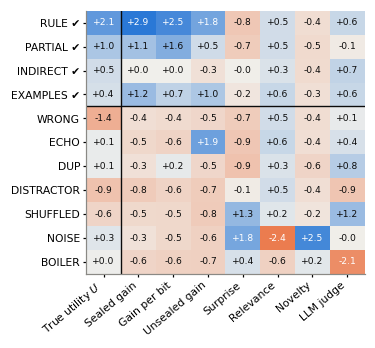

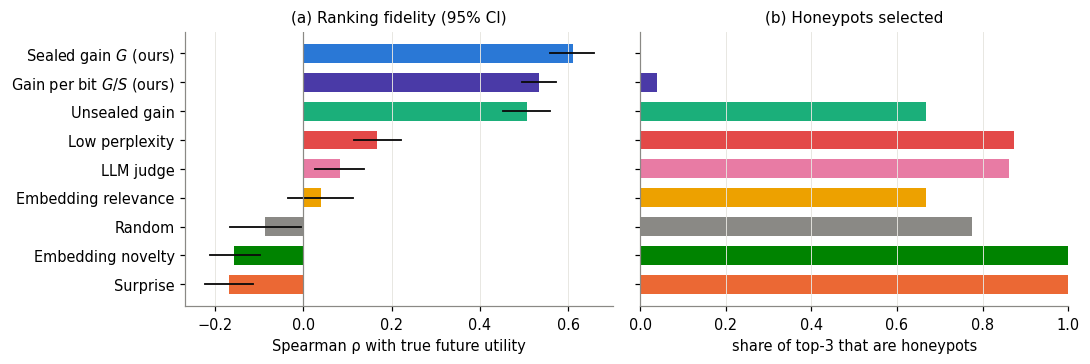

In [ ]:
# ---- 3.6  Figure 3: which signal is fooled by which document type (within-world z-scores) ----
HEAT_SIGS = ["U", "CP", "CP_ratio", "IG_full", "surprise", "relevance", "novelty"] + (["judge"] if CFG["judge"] else [])
Z = E1T.copy()
for s in HEAT_SIGS:
    Z[s] = Z.groupby("world")[s].transform(lambda x: (x - x.mean()) / (x.std() + 1e-9))
H = Z.groupby("type")[HEAT_SIGS].mean().reindex(TYPE_ORDER)
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", [PAL["orange"], "#f1f0ec", PAL["blue"]])
HEAT_LAB = {"U": "True utility $U$", "CP": "Sealed gain" if LAM == 0 else "CP (ours)", "CP_ratio": "Gain per bit", "IG_full": "Unsealed gain",
            "surprise": "Surprise", "relevance": "Relevance", "novelty": "Novelty", "judge": "LLM judge"}
def plot_heatmap(Hm, name="fig3_e1_heatmap"):
    """Column-width paper figure: rows = document types, columns = signals, cells = mean within-world z-score."""
    fig, ax = plt.subplots(figsize=(3.5, 3.25))
    vmax = np.nanmax(np.abs(Hm.values)); ax.imshow(Hm.values, cmap=div, vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(Hm.shape[1])); ax.set_xticklabels([HEAT_LAB.get(s, s) for s in Hm.columns], rotation=40, ha="right", fontsize=7)
    ax.set_yticks(range(Hm.shape[0])); ax.set_yticklabels([t + (" ✔" if t in USEFUL_TYPES else "") for t in Hm.index], fontsize=7)
    for (r, c), v in np.ndenumerate(Hm.values):
        if np.isfinite(v): ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=6, color="#0b0b0b" if abs(v) < 0.6 * vmax else "white")
    ax.axhline(len(USEFUL_TYPES) - 0.5, color="#0b0b0b", lw=0.9); ax.axvline(0.5, color="#0b0b0b", lw=0.9); ax.grid(False)
    ax.tick_params(length=2, pad=2)
    savefig(fig, name)
plot_heatmap(H)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
order = sorted([s for s in SIGNALS if s != "oracle"], key=lambda s: met[s].rho.mean())
for i, s in enumerate(order):
    m, lo, hi = boot_ci(met[s].rho)
    ax[0].barh(i, m, color=SIG_STYLE[s][1], height=0.65); ax[0].plot([lo, hi], [i, i], color="#0b0b0b", lw=1.2)
    ax[1].barh(i, met[s].honey_at_k.mean(), color=SIG_STYLE[s][1], height=0.65)
for a in ax: a.set_yticks(range(len(order))); a.set_yticklabels([SIG_STYLE[s][0] for s in order]); a.grid(axis="y", visible=False)
ax[0].axvline(0, color=PAL["grey"], lw=0.8)
ax[0].set(xlabel="Spearman ρ with true future utility", title="(a) Ranking fidelity (95% CI)")
ax[1].set(xlabel="share of top-3 that are honeypots", title="(b) Honeypots selected", xlim=(0, 1)); ax[1].set_yticklabels([])
savefig(fig, "fig4_e1_bars")

## E4 — Noise dose-response: one useful document hidden among $k$ honeypots
How often does each signal pick the single useful document as the number of honeypots grows? Scores do not depend on the rest of the pool, so we resample pools from the E1 scores (200 draws per world and per $k$).

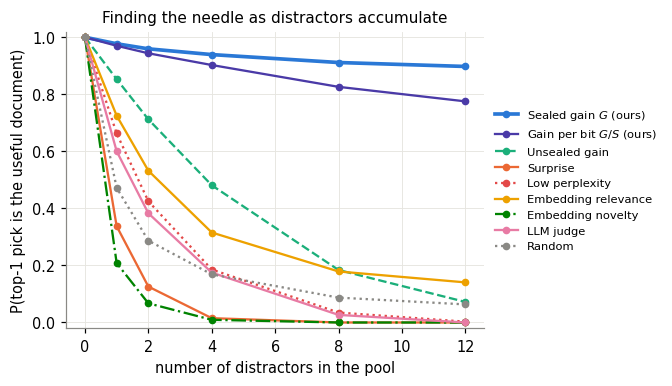

✔ SUPPORTED   With many honeypots, compression progress still finds the useful document while surprise collapses
      P(top-1 useful) at 12 honeypots: CP=0.90, surprise=0.00, CP_ratio=0.78, IG_full=0.07, low_ppl=0.00, relevance=0.14, novelty=0.00, judge=0.00, random=0.06


In [ ]:
# ---- 3.7  E4 ----
KS = [0, 1, 2, 4, 8, 12]
def dose_response(df, sig, R=200, seed=0):
    rng = np.random.default_rng(seed); out = {k: [] for k in KS}
    for wid, g in df.groupby("world"):
        U_idx, H_idx = np.where(g.useful.values)[0], np.where(~g.useful.values)[0]; s = g[sig].values
        for k in KS:
            hits = 0
            for _ in range(R):
                u = rng.choice(U_idx); hs = rng.choice(H_idx, size=min(k, len(H_idx)), replace=False)
                hits += s[u] > (s[hs].max() if k else -np.inf)
            out[k].append(hits / R)
    return {k: np.array(v) for k, v in out.items()}
E4_SIGS = [s for s in ["CP", "CP_ratio", "IG_full", "surprise", "low_ppl", "relevance", "novelty", "judge", "random"] if s in SIGNALS]
dose = {s: dose_response(E1T, s) for s in E4_SIGS}
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for s in E4_SIGS:
    mu = [dose[s][k].mean() for k in KS]
    ax.plot(KS, mu, marker="o", ms=4, color=SIG_STYLE[s][1], ls=SIG_STYLE[s][2], lw=2.4 if s == "CP" else 1.5, label=SIG_STYLE[s][0])
ax.set(xlabel="number of distractors in the pool", ylabel="P(top-1 pick is the useful document)", ylim=(-0.02, 1.02),
       title="Finding the needle as distractors accumulate")
ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1, 0.5))
savefig(fig, "fig7_e4_dose_response")
RESULTS["E4"] = {s: {k: float(dose[s][k].mean()) for k in KS} for s in E4_SIGS}
claim("E4_dose", "With many honeypots, compression progress still finds the useful document while surprise collapses",
      dose["CP"][12].mean() > 0.7 and dose["surprise"][12].mean() < 0.3,
      f"P(top-1 useful) at 12 honeypots: CP={dose['CP'][12].mean():.2f}, surprise={dose['surprise'][12].mean():.2f}, "
      + ", ".join(f"{s}={dose[s][12].mean():.2f}" for s in E4_SIGS if s not in ("CP", "surprise")))

## E8 — Ablations: cost weight λ, sealing, audit size, and the boundedness certificate (P3)

               CP1>0 (unsealed)  CP1>0 (sealed)  mean S (bits)  mean G_seal (bits)  mean U (bits)
Document type                                                                                    
RULE                        0.0             0.0         194.21               96.99          21.55
PARTIAL                     0.0             0.0         130.40               46.27           8.87
INDIRECT                    0.0             0.0         165.61               14.33           2.42
EXAMPLES                    0.0             0.0         244.90               50.23           2.14
WRONG                       0.0             0.0         247.45                3.09         -19.66
ECHO                        0.0             0.0          68.25               -1.02          -1.94
DUP                         0.0             0.0          37.55                4.40          -2.01
DISTRACTOR                  0.0             0.0         626.20               -8.26         -14.39
SHUFFLED            

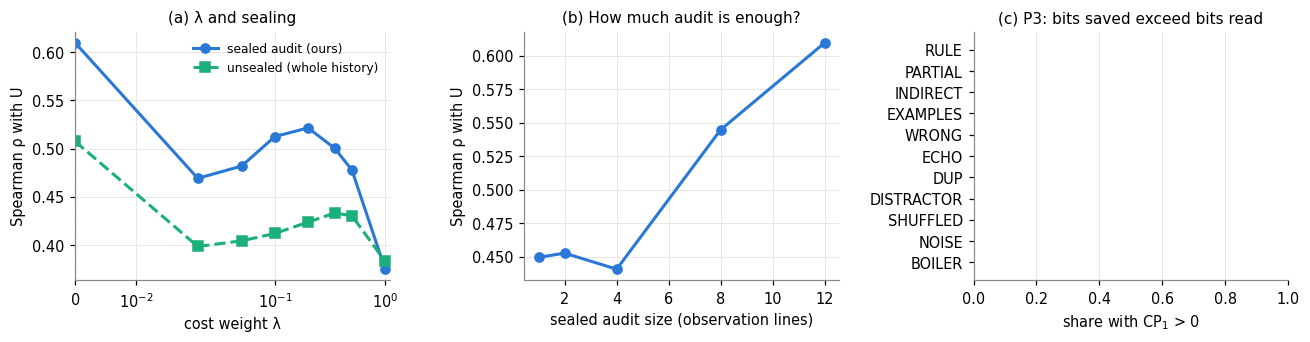

✔ SUPPORTED   Sealing the audit matters: unsealed gain is fooled by echoes of the agent's own history
      mean rank of ECHO docs (1 = top): unsealed 1.9 vs sealed CP 12.5
✘ NOT SUPPORTED   LLM observers are measurably bounded (P3): some documents save more bits than they cost to read
      max share of useful-type docs with sealed CP_1>0: 0.00 (a coherent Bayesian coder would give 0); the full field guide saves 0.502 audit bits per bit read, i.e. it breaks even at λ≈0.502


In [ ]:
# ---- 3.8  E8 ----
lam_rows = []
for lam in CFG["lambdas"]:
    d = E1T.assign(CP_sealed=E1T.G_seal - lam * E1T.S, CP_unsealed=E1T.G_full - lam * E1T.S)
    lam_rows.append(dict(lam=lam, sealed=rank_metrics(d, "CP_sealed").rho.mean(), unsealed=rank_metrics(d, "CP_unsealed").rho.mean(),
                         echo_top3_unsealed=rank_metrics(d, "CP_unsealed").pipe(lambda m: m.honey_at_k.mean())))
LAMDF = pd.DataFrame(lam_rows)
n_aud = len(WORLDS[0].h_aud); aud_rows = []
for j in sorted({1, 2, 4, 8, n_aud}):
    d = E1T.assign(CPj=E1T.G_seal_lines.apply(lambda a: a[:j].sum()) - LAM * (j / n_aud) * E1T.S)
    aud_rows.append(dict(audit_lines=j, rho=rank_metrics(d, "CPj").rho.mean()))
AUDDF = pd.DataFrame(aud_rows)
echo_rank = lambda sig: E1T.groupby("world").apply(lambda g: (g[sig].rank(ascending=False)[g.type == "ECHO"]).mean()).mean()
bounded = E1T.groupby("type").apply(lambda g: pd.Series({"CP1>0 (unsealed)": (g.G_full - g.S_front > 0).mean(),
                                                         "CP1>0 (sealed)": (g.G_seal - g.S > 0).mean(),
                                                         "mean S (bits)": g.S.mean(), "mean G_seal (bits)": g.G_seal.mean(),
                                                         "mean U (bits)": g.U.mean()})).reindex(TYPE_ORDER)
bounded.index.name = "Document type"
to_latex(bounded, "e8_boundedness", "Per document type: how often MDL progress CP$_1$ is positive (P3: impossible for a coherent Bayesian coder), with mean surprise, sealed gain and true utility.", "{:.2f}")
print(bounded.round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(LAMDF.lam, LAMDF.sealed, marker="o", color=SIG_STYLE["CP"][1], label="sealed audit (ours)")
ax[0].plot(LAMDF.lam, LAMDF.unsealed, marker="s", color=SIG_STYLE["IG_full"][1], ls="--", label="unsealed (whole history)")
ax[0].axvline(LAM, color=PAL["grey"], lw=0.8, ls=":"); ax[0].set_xscale("symlog", linthresh=0.02); ax[0].set_xlim(0, 1.1)
ax[0].set(xlabel="cost weight λ", ylabel="Spearman ρ with U", title="(a) λ and sealing"); ax[0].legend(fontsize=8)
ax[1].plot(AUDDF.audit_lines, AUDDF.rho, marker="o", color=SIG_STYLE["CP"][1])
ax[1].set(xlabel="sealed audit size (observation lines)", ylabel="Spearman ρ with U", title="(b) How much audit is enough?")
bp = bounded["CP1>0 (sealed)"].fillna(0)
ax[2].barh(range(len(bp)), bp.values, color=[PAL["blue"] if t in USEFUL_TYPES else PAL["grey"] for t in bp.index], height=0.65)
ax[2].set_yticks(range(len(bp))); ax[2].set_yticklabels(bp.index); ax[2].invert_yaxis(); ax[2].grid(axis="y", visible=False)
ax[2].set(xlabel="share with CP$_1$ > 0", title="(c) P3: bits saved exceed bits read", xlim=(0, 1))
savefig(fig, "fig12_e8_ablations")
RESULTS["E8"] = dict(lambda_sweep=LAMDF.to_dict("list"), audit=AUDDF.to_dict("list"), boundedness=bounded.to_dict())
useful_bounded = bounded.loc[["RULE", "PARTIAL", "INDIRECT"], "CP1>0 (sealed)"].max()
claim("E8_sealing", "Sealing the audit matters: unsealed gain is fooled by echoes of the agent's own history",
      echo_rank("IG_full") < echo_rank("CP"),
      f"mean rank of ECHO docs (1 = top): unsealed {echo_rank('IG_full'):.1f} vs sealed CP {echo_rank('CP'):.1f}")
rule_rate = (E1T[E1T.type == "RULE"].G_seal / E1T[E1T.type == "RULE"].S).mean()
claim("E8_bounded", "LLM observers are measurably bounded (P3): some documents save more bits than they cost to read",
      useful_bounded > 0, f"max share of useful-type docs with sealed CP_1>0: {useful_bounded:.2f} (a coherent Bayesian coder would give 0); "
      f"the full field guide saves {rule_rate:.3f} audit bits per bit read, i.e. it breaks even at λ≈{rule_rate:.3f}")

### E8b — The boundedness certificate over a longer history (P3)
P3 says a coherent Bayesian coder has $\mathrm{CP}_1(D)=G(D)-S(D)\le 0$ **however long the history is**. It already marginalizes over every explanation, so no document is ever worth more than its own description length. A computationally bounded observer is different: an explanation keeps paying on every new observation it explains, while its reading cost is paid once. We re-score each test world with a **72-line** sealed audit and plot $\sum_{j\le n}G_j - S$ against the audit length $n$. If the curve for the true field guide crosses zero, the LLM is doing something no coherent Bayesian coder can do.

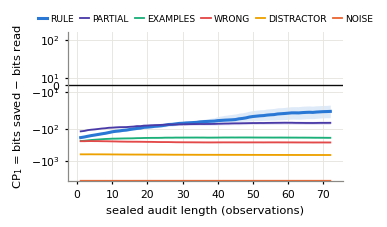

                             mean CP1 (bits)  share CP1>0
Document (audit = 72 lines)                              
DISTRACTOR                           -660.84         0.00
EXAMPLES                             -187.50         0.00
NOISE                               -4366.74         0.00
PARTIAL                               -62.65         0.00
RULE                                  -38.03         0.03
WRONG                                -263.45         0.00
RULE break-even audit length per world: [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, 54.0, nan, nan, nan, 43.0, nan, nan, nan, nan, nan, nan, nan, nan]
✘ NOT SUPPORTED   Over a long enough history, the true explanation saves more bits than it costs (CP_1 > 0), which is impossible for a coherent Bayesian coder
      at 72 audit lines: RULE CP_1>0 in 3% of worlds (mean -38 bits; median break-even 48 lines); WRONG mean -263 bits


In [ ]:
# ---- 3.8b  E8b: MDL progress vs audit length ----
N_LONG = 72   # FULL v4 run: the true guide's curve was still rising at 36 lines and projected to cross zero near 45
E8B_DOCS = ["RULE", "PARTIAL_1", "EXAMPLES", "WRONG_1", "DISTRACTOR_1", "NOISE_1"]
e8b = []
for wid in sorted(TEST):
    weL = WorldEval(World(wid, n_aud=N_LONG), SC)
    for d in E8B_DOCS:
        t = weL.terms(M0, d); cum = np.cumsum(t["G_seal_lines"])
        for n in range(1, N_LONG + 1): e8b.append(dict(world=wid, key=d, type=dtype_of(d), n=n, CP1=cum[n - 1] - t["S"]))
    del weL
E8B = pd.DataFrame(e8b)
fig, ax = plt.subplots(figsize=(3.5, 2.15))   # column-width paper figure
for d, col in zip(E8B_DOCS, [PAL["blue"], PAL["violet"], PAL["aqua"], PAL["red"], PAL["yellow"], PAL["orange"]]):
    g = E8B[E8B.key == d].groupby("n").CP1; mu, se = g.mean(), g.std() / np.sqrt(g.count())
    ax.plot(mu.index, mu.values, color=col, lw=2.0 if d == "RULE" else 1.2, label=d.split("_")[0])
    ax.fill_between(mu.index, mu - 1.96 * se, mu + 1.96 * se, color=col, alpha=0.15, lw=0)
ax.axhline(0, color="#0b0b0b", lw=0.9)
ax.set_yscale("symlog", linthresh=50)
ax.set_xlabel("sealed audit length (observations)", fontsize=7.5); ax.set_ylabel("CP$_1$ = bits saved − bits read", fontsize=7.5)
ax.tick_params(labelsize=7, length=2)
ax.legend(fontsize=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, columnspacing=0.7, handlelength=1.0, handletextpad=0.3)
savefig(fig, "fig13_e8b_breakeven")
fin8 = E8B[E8B.n == N_LONG].groupby("type").CP1.agg(["mean", lambda x: (x > 0).mean()]); fin8.columns = ["mean CP1 (bits)", "share CP1>0"]
def breakeven(g):
    pos = g.sort_values("n").query("CP1 > 0"); return pos.n.min() if len(pos) else np.nan
be = E8B[E8B.key == "RULE"].groupby("world").apply(breakeven)
fin8.index.name = f"Document (audit = {N_LONG} lines)"
to_latex(fin8, "e8b_breakeven", f"E8b: MDL progress CP$_1$ after a {N_LONG}-line sealed audit. P3: a coherent Bayesian coder has CP$_1\\le 0$ always.", "{:.2f}")
print(fin8.round(2).to_string()); print("RULE break-even audit length per world:", be.tolist())
RESULTS["E8b"] = dict(final=fin8.to_dict(), rule_breakeven=be.tolist())
claim("E8b_bounded", "Over a long enough history, the true explanation saves more bits than it costs (CP_1 > 0), which is impossible for a coherent Bayesian coder",
      fin8.loc["RULE", "share CP1>0"] > 0.5 and fin8.loc["WRONG", "mean CP1 (bits)"] < 0,
      f"at {N_LONG} audit lines: RULE CP_1>0 in {fin8.loc['RULE','share CP1>0']:.0%} of worlds (mean {fin8.loc['RULE','mean CP1 (bits)']:.0f} bits; "
      f"median break-even {np.nanmedian(be) if be.notna().any() else float('nan'):.0f} lines); WRONG mean {fin8.loc['WRONG','mean CP1 (bits)']:.0f} bits")

### E9 — Matched ablation: the same test worlds without the gazetteer
Without the gazetteer the invented vocabulary is new to the observer, so any document that merely *names* the land's words earns gain (lexical priming). This re-scores the test worlds with the gazetteer removed from memory and compares the true and the wrong field guides.

In [ ]:
# ---- 3.8c  E9: no-gazetteer ablation ----
GAZ = None
if CFG["gazetteer"]:
    NOGAZ = ("PARTIAL_0",)
    E9 = pd.concat([add_cp(signals_for(EVALS[wid], NOGAZ, E1_KEYS, use_judge=False, rng=np.random.default_rng(wid), unsealed=False), LAM)
                    for wid in sorted(TEST)], ignore_index=True)
    m9 = rank_metrics(E9, "CP")
    g_ = lambda df, t: float(df[df.type == t].G_seal.mean())
    GAZ = dict(rho_with=float(met["CP"].rho.mean()), rho_without=float(m9.rho.mean()),
               rule_with=g_(E1T, "RULE"), wrong_with=g_(E1T, "WRONG"), shuffled_with=g_(E1T, "SHUFFLED"),
               rule_without=g_(E9, "RULE"), wrong_without=g_(E9, "WRONG"), shuffled_without=g_(E9, "SHUFFLED"),
               wrong3_with=float(met["CP"].wrong_at_k.mean()), wrong3_without=float(m9.wrong_at_k.mean()))
    RESULTS["E9"] = GAZ
    g9 = pd.DataFrame({"with gazetteer": [GAZ["rho_with"], GAZ["rule_with"], GAZ["wrong_with"], GAZ["shuffled_with"], GAZ["wrong3_with"]],
                       "without": [GAZ["rho_without"], GAZ["rule_without"], GAZ["wrong_without"], GAZ["shuffled_without"], GAZ["wrong3_without"]]},
                      index=["Spearman ρ with U", "RULE sealed gain (bits)", "WRONG sealed gain (bits)", "SHUFFLED sealed gain (bits)", "wrong rule in top-3"])
    g9.index.name = "Quantity"; to_latex(g9, "e9_gazetteer", "E9: the test worlds scored with and without the gazetteer in memory.", "{:.2f}")
    print(g9.round(2).to_string())
    claim("E9_vocabulary", "Without the gazetteer, a wrong field guide earns substantial sealed gain from vocabulary alone; with it, the gain disappears",
          GAZ["wrong_without"] > 5 * max(GAZ["wrong_with"], 1.0),
          f"WRONG sealed gain: {GAZ['wrong_without']:.1f} bits without vs {GAZ['wrong_with']:.1f} with (RULE: {GAZ['rule_without']:.1f} vs {GAZ['rule_with']:.1f})")

                             with gazetteer  without
Quantity                                            
Spearman ρ with U                      0.61     0.06
RULE sealed gain (bits)               96.99   332.46
WRONG sealed gain (bits)               3.09   221.45
SHUFFLED sealed gain (bits)            0.28   195.83
wrong rule in top-3                    0.00     0.94
✔ SUPPORTED   Without the gazetteer, a wrong field guide earns substantial sealed gain from vocabulary alone; with it, the gain disappears
      WRONG sealed gain: 221.5 bits without vs 3.1 with (RULE: 332.5 vs 97.0)


## E7 — Amortized curiosity: can the agent predict progress before reading?
§3.2 of the paper uses a model that *predicts the predictor's improvements*. Two cheap versions:
1. **Peek**: compute CP from only $k$ tokens of the document, taken either from its **head** or from its **middle** (headers are often generic), extrapolating its reading cost from its length.
2. **Learned predictor**: ridge regression from the peek's features (a hidden-state embedding of the first 16 tokens, plus peek surprise and peek gain) to full CP, trained leave-one-world-out.

                                    read  rho_U  rho_fullCP
Method                                                     
peek 8 tokens (head)               0.085  0.067       0.240
peek 16 tokens (head)              0.169  0.149       0.194
peek 32 tokens (head)              0.330  0.431       0.513
peek 8 tokens (mid)                0.085  0.111       0.019
peek 16 tokens (mid)               0.169  0.331       0.287
peek 32 tokens (mid)               0.330  0.477       0.517
learned predictor (16-token peek)  0.169  0.201       0.490
full CP (reads everything)         1.000  0.610       1.000
surprise (reads everything)        1.000 -0.168         NaN


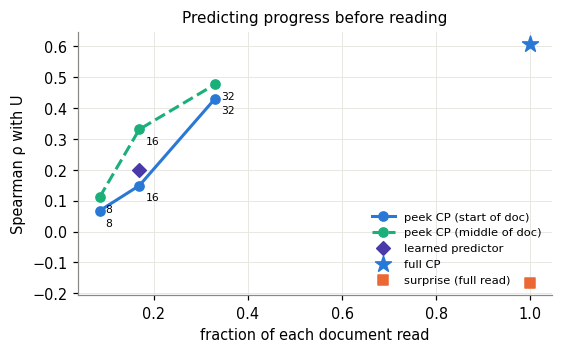

✔ SUPPORTED   A short peek (≤32 tokens) recovers most of full compression progress's ranking quality
      best peek = peek 32 tokens (mid): ρ=0.48 reading 33% vs full CP ρ=0.61; 16-token head peek ρ=0.15


In [ ]:
# ---- 3.9  E7 ----
PEEKS = [8, 16, 32]
e7 = []
for wid in sorted(TEST):
    we = EVALS[wid]; we.run([(M0, None, "base")] + [(M0, (c, k, pos), "seal") for c in E1_KEYS for k in PEEKS for pos in ("head", "mid")])
    full = E1T[E1T.world == wid].set_index("key")
    for c in E1_KEYS:
        n_full = len(we.cand_ids(c))
        for k in PEEKS:
          for pos in ("head", "mid"):
            t = we.terms(M0, (c, k, pos))
            e7.append(dict(world=wid, key=c, k=k, pos=pos, U=full.loc[c, "U"], CP_full=full.loc[c, "CP"], read_frac=min(1, k / n_full),
                           peek=t["G_seal"] - LAM * t["S_doc"] / max(t["n_D"], 1) * n_full, g=t["G_seal"], s=t["S_doc"] / max(t["n_D"], 1)))
E7 = pd.DataFrame(e7)
peek_rows = []
for pos in ("head", "mid"):
  for k in PEEKS:
    d = E7[(E7.k == k) & (E7.pos == pos)]
    r_u = d.groupby("world").apply(lambda g: stats.spearmanr(g.peek, g.U).correlation).mean()
    r_f = d.groupby("world").apply(lambda g: stats.spearmanr(g.peek, g.CP_full).correlation).mean()
    peek_rows.append(dict(method=f"peek {k} tokens ({pos})", read=d.read_frac.mean(), rho_U=r_u, rho_fullCP=r_f))
# learned predictor on 16-token prefixes
feats, ys, groups, keys = [], [], [], []
for wid in sorted(TEST):
    we = EVALS[wid]; emb = we.sc.embed_ids([we.sc.ids(we.docs[c])[:16] for c in E1_KEYS])
    d = E7[(E7.world == wid) & (E7.k == 16) & (E7.pos == "head")].set_index("key").loc[E1_KEYS]
    y = (d.CP_full - d.CP_full.mean()) / (d.CP_full.std() + 1e-9)
    feats.append(np.hstack([emb, d[["g", "s"]].values])); ys.append(y.values); groups += [wid] * len(E1_KEYS); keys += E1_KEYS
X, Y, G_ = np.vstack(feats), np.concatenate(ys), np.array(groups)
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
pred = np.zeros_like(Y)
for wid in np.unique(G_):
    tr = G_ != wid
    if tr.sum() < 5: continue
    scl = StandardScaler().fit(X[tr]); mdl = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(scl.transform(X[tr]), Y[tr])
    pred[~tr] = mdl.predict(scl.transform(X[~tr]))
E7L = E7[(E7.k == 16) & (E7.pos == "head")].copy().set_index(["world", "key"]).loc[list(zip(G_, keys))].assign(pred=pred).reset_index()
peek_rows.append(dict(method="learned predictor (16-token peek)", read=E7[(E7.k == 16) & (E7.pos == "head")].read_frac.mean(),
                      rho_U=E7L.groupby("world").apply(lambda g: stats.spearmanr(g.pred, g.U).correlation).mean(),
                      rho_fullCP=E7L.groupby("world").apply(lambda g: stats.spearmanr(g.pred, g.CP_full).correlation).mean()))
peek_rows.append(dict(method="full CP (reads everything)", read=1.0, rho_U=met["CP"].rho.mean(), rho_fullCP=1.0))
peek_rows.append(dict(method="surprise (reads everything)", read=1.0, rho_U=met["surprise"].rho.mean(), rho_fullCP=np.nan))
T7 = pd.DataFrame(peek_rows).set_index("method"); T7.index.name = "Method"
to_latex(T7, "e7_amortized", "E7: amortized compression progress. `read' = mean fraction of each document the agent must read.", "{:.2f}")
print(T7.round(3).to_string())
RESULTS["E7"] = T7.to_dict()
fig, ax = plt.subplots(figsize=(5.2, 3.3))
for pos, col, ls in (("head", SIG_STYLE["CP"][1], "-"), ("mid", PAL["aqua"], "--")):
    pk = T7.loc[[f"peek {k} tokens ({pos})" for k in PEEKS]]
    ax.plot(pk.read, pk.rho_U, marker="o", color=col, ls=ls, label=f"peek CP ({'start' if pos == 'head' else 'middle'} of doc)")
    for k, (x_, y_) in zip(PEEKS, pk[["read", "rho_U"]].values): ax.annotate(f"{k}", (x_, y_), xytext=(4, -10), textcoords="offset points", fontsize=7)
lp = T7.loc["learned predictor (16-token peek)"]
ax.scatter([lp.read], [lp.rho_U], marker="D", s=40, color=SIG_STYLE["CP_ratio"][1], label="learned predictor", zorder=3)
ax.scatter([1.0], [met["CP"].rho.mean()], marker="*", s=120, color=SIG_STYLE["CP"][1], label="full CP", zorder=3)
ax.scatter([1.0], [met["surprise"].rho.mean()], marker="s", s=40, color=SIG_STYLE["surprise"][1], label="surprise (full read)", zorder=3)
ax.set(xlabel="fraction of each document read", ylabel="Spearman ρ with U", title="Predicting progress before reading")
ax.legend(fontsize=7.5, loc="lower right"); savefig(fig, "fig11_e7_amortized")
best_peek = max([f"peek {k} tokens ({p})" for k in PEEKS for p in ("head", "mid")], key=lambda m: T7.loc[m, "rho_U"])
claim("E7_amortized", "A short peek (≤32 tokens) recovers most of full compression progress's ranking quality",
      T7.loc[best_peek, "rho_U"] > 0.6 * met["CP"].rho.mean() and T7.loc[best_peek, "rho_U"] > met["surprise"].rho.mean(),
      f"best peek = {best_peek}: ρ={T7.loc[best_peek,'rho_U']:.2f} reading {T7.loc[best_peek,'read']:.0%} vs full CP ρ={met['CP'].rho.mean():.2f}; "
      f"16-token head peek ρ={T7.loc['peek 16 tokens (head)','rho_U']:.2f}")

## E2 — A budgeted curious agent
The agent starts with only the gazetteer in memory and a pool of 19 documents (the E1 pool plus the class-0 entry). At each step it reads the document its signal ranks highest, adds it to memory and re-scores the rest. Signals are recomputed given the *current* memory, so boredom can emerge. We track how well the agent predicts the future (attribute accuracy and bits per token on $Q$) after each read.

  agent world 1/20 (26s)
  agent world 2/20 (55s)
  agent world 3/20 (85s)
  agent world 4/20 (118s)
  agent world 5/20 (150s)
  agent world 6/20 (178s)
  agent world 7/20 (208s)
  agent world 8/20 (239s)
  agent world 9/20 (272s)
  agent world 10/20 (305s)
  agent world 11/20 (338s)
  agent world 12/20 (366s)
  agent world 13/20 (400s)
  agent world 14/20 (429s)
  agent world 15/20 (460s)
  agent world 16/20 (492s)
  agent world 17/20 (520s)
  agent world 18/20 (550s)
  agent world 19/20 (579s)
  agent world 20/20 (610s)
                          future attr. accuracy future bits/token honeypots read wrong rules read tokens read
Agent's signal                                                                                               
Sealed gain $G$ (ours)        0.98 [0.97, 0.99]             1.082           1.60             0.00         941
Gain per bit $G/S$ (ours)     0.98 [0.97, 0.99]             1.086           1.50             0.00         868
Unsealed gain                 0.

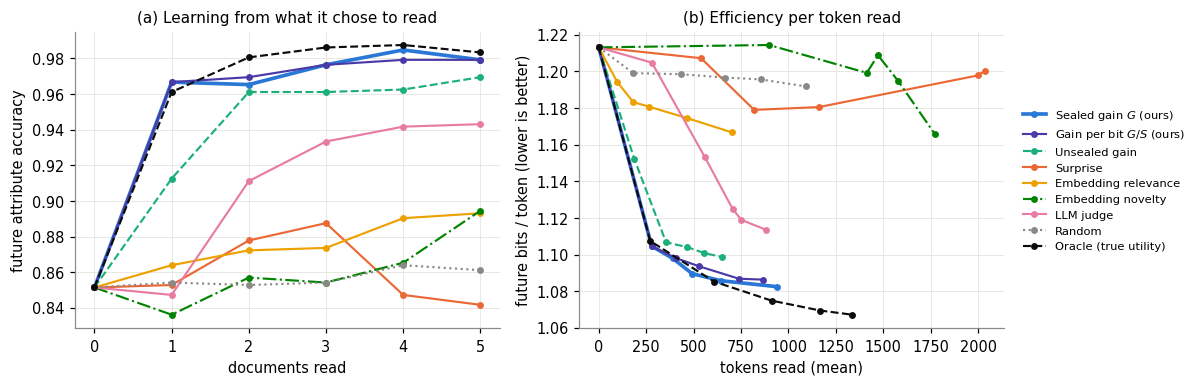

✔ SUPPORTED   An agent that reads by compression progress predicts the future better than agents using any baseline signal
      final future accuracy: CP 0.979 vs best baseline IG_full 0.969 (Wilcoxon p=0.07); future bits/token: CP 1.082 vs best baseline IG_full 1.099 (p=0.0049); oracle 0.983 / 1.067


In [ ]:
# ---- 3.10  E2 (+ E3 logs) ----
AGENT_STRATS = [s for s in ["CP", "CP_ratio", "IG_full", "surprise", "relevance", "novelty", "judge", "random", "oracle"] if s in SIGNALS]
PASS_STRATS = {"CP", "CP_ratio", "IG_full", "surprise", "oracle"}
AGENT_WORLDS = sorted(TEST)[:CFG["n_worlds_agent"]]
POOL = E1_KEYS + ["PARTIAL_0"]
boredom_log = []

def run_agent(we, strat, wid, mode="reads", limit=None, log_boredom=False):
    """One reading agent. mode='reads': read `limit` documents. mode='tokens': read until a budget of `limit`
    document tokens is spent (only documents that still fit are candidates; at most 10 reads)."""
    mem, tokens, rng, rows = BASE_MEM, 0, np.random.default_rng(wid), []
    rows.append(dict(world=wid, strat=strat, mode=mode, step=0, tokens=0, pick=None, useful=None, **we.state(mem)))
    for step in range(1, (limit if mode == "reads" else 10) + 1):
        rem = [c for c in POOL if c not in mem]
        if mode == "tokens": rem = [c for c in rem if tokens + len(we.cand_ids(c)) <= limit]
        if not rem: break
        if strat in PASS_STRATS:
            df = signals_for(we, mem, rem, use_judge=False, rng=rng, unsealed=(strat == "IG_full"))
            df = add_cp(df, LAM).assign(oracle=lambda d: d.U)
            if log_boredom:
                boredom_log.extend(dict(world=wid, step=step, key=r.key, type=r.type, CP=r.CP, G_seal=r.G_seal, U=r.U) for r in df.itertuples())
            pick = df.key.values[int(np.argmax(df[strat].values))]
        elif strat == "random": pick = rem[int(rng.integers(len(rem)))]
        elif strat == "judge": pick = rem[int(np.argmax(we.judge(mem, rem)))]
        else:
            E = we.embed(rem + ["__hist__"] + list(mem)); ec, eh, em = E[:len(rem)], E[len(rem)], E[len(rem) + 1:]
            sc_ = ec @ eh if strat == "relevance" else (1 - (em @ ec.T).max(0) if len(mem) else np.ones(len(rem)) + 1e-6 * rng.random(len(rem)))
            pick = rem[int(np.argmax(sc_))]
        mem = mem + (pick,); tokens += len(we.cand_ids(pick))
        rows.append(dict(world=wid, strat=strat, mode=mode, step=step, tokens=tokens, pick=pick,
                         useful=dtype_of(pick) in USEFUL_TYPES, **we.state(mem)))
    return rows

agent_log = []; t0 = time.time()
for wi, wid in enumerate(AGENT_WORLDS):
    for strat in AGENT_STRATS:
        agent_log += run_agent(EVALS[wid], strat, wid, "reads", CFG["agent_steps"], log_boredom=(strat == "CP"))
    print(f"  agent world {wi+1}/{len(AGENT_WORLDS)} ({time.time()-t0:.0f}s)")
AG = pd.DataFrame(agent_log); BOR = pd.DataFrame(boredom_log)

fin = AG[AG.step == CFG["agent_steps"]].set_index(["strat", "world"]).sort_index()
picks = AG[AG.step > 0]
rows = {}
for s in AGENT_STRATS:
    f = fin.loc[s]; pk = picks[picks.strat == s]
    rows[SIG_STYLE[s][0]] = {"future attr. accuracy": fmt_ci(boot_ci(f.q_acc), 2), "future bits/token": f"{f.q_bpt.mean():.3f}",
                             "honeypots read": f"{(~pk.useful.astype(bool)).groupby(pk.world).sum().mean():.2f}",
                             "wrong rules read": f"{pk.pick.fillna('').str.startswith('WRONG').groupby(pk.world).sum().mean():.2f}",
                             "tokens read": f"{f.tokens.mean():.0f}"}
T2 = pd.DataFrame(rows).T; T2.index.name = "Agent's signal"
to_latex(T2, "e2_agent", f"E2: budgeted agent after {CFG['agent_steps']} reads, {len(AGENT_WORLDS)} test worlds. Mean [95\\% CI].")
print(T2.to_string())
RESULTS["E2"] = {s: dict(q_acc=boot_ci(fin.loc[s].q_acc), q_bpt=float(fin.loc[s].q_bpt.mean())) for s in AGENT_STRATS}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s in AGENT_STRATS:
    g = AG[AG.strat == s].groupby("step")
    ax[0].plot(g.q_acc.mean().index, g.q_acc.mean().values, marker="o", ms=3.5, color=SIG_STYLE[s][1], ls=SIG_STYLE[s][2],
               lw=2.4 if s == "CP" else 1.4, label=SIG_STYLE[s][0])
    ax[1].plot(g.tokens.mean().values, g.q_bpt.mean().values, marker="o", ms=3.5, color=SIG_STYLE[s][1], ls=SIG_STYLE[s][2], lw=2.4 if s == "CP" else 1.4)
ax[0].set(xlabel="documents read", ylabel="future attribute accuracy", title="(a) Learning from what it chose to read")
ax[1].set(xlabel="tokens read (mean)", ylabel="future bits / token (lower is better)", title="(b) Efficiency per token read")
ax[1].legend(*ax[0].get_legend_handles_labels(), fontsize=7.5, loc="center left", bbox_to_anchor=(1.02, 0.5))
savefig(fig, "fig5_e2_agent")
nonoracle = [s for s in AGENT_STRATS if s not in ("CP", "CP_ratio", "oracle")]
best_b = max(nonoracle, key=lambda s: fin.loc[s].q_acc.mean())
pv = wilcoxon_p(fin.loc["CP"].q_acc.values, fin.loc[best_b].q_acc.values)
best_bits = min(nonoracle, key=lambda s: fin.loc[s].q_bpt.mean())
pb = wilcoxon_p(fin.loc["CP"].q_bpt.values, fin.loc[best_bits].q_bpt.values)
claim("E2_agent", "An agent that reads by compression progress predicts the future better than agents using any baseline signal",
      fin.loc["CP"].q_acc.mean() >= fin.loc[best_b].q_acc.mean() and fin.loc["CP"].q_bpt.mean() <= fin.loc[best_bits].q_bpt.mean(),
      f"final future accuracy: CP {fin.loc['CP'].q_acc.mean():.3f} vs best baseline {best_b} {fin.loc[best_b].q_acc.mean():.3f} (Wilcoxon p={pv:.2g}); "
      f"future bits/token: CP {fin.loc['CP'].q_bpt.mean():.3f} vs best baseline {best_bits} {fin.loc[best_bits].q_bpt.mean():.3f} (p={pb:.2g}); "
      f"oracle {fin.loc['oracle'].q_acc.mean():.3f} / {fin.loc['oracle'].q_bpt.mean():.3f}")

### E2b — The same agents under a token budget
In E2 every agent reads the same *number* of documents, so reading is free. Here each agent may read at most a fixed number of document **tokens**: 1.5 times the length of that world's full field guide, so it can afford the guide and one short document, or several short ones. This is where the cost term should matter: the ratio $G/S$ (bits saved per bit read) is the cost-aware form of compression progress.

In [ ]:
# ---- 3.10b  E2b: token-budget agents ----
BUDGET = {wid: int(round(CFG["agent_budget_x"] * len(EVALS[wid].cand_ids("RULE")))) for wid in AGENT_WORLDS}
print(f"token budgets: {CFG['agent_budget_x']} x the full guide = {np.mean(list(BUDGET.values())):.0f} tokens on average")
budget_log = []; t0 = time.time()
for wi, wid in enumerate(AGENT_WORLDS):
    for strat in AGENT_STRATS:
        budget_log += run_agent(EVALS[wid], strat, wid, "tokens", BUDGET[wid])
    print(f"  budget-agent world {wi+1}/{len(AGENT_WORLDS)} ({time.time()-t0:.0f}s)")
AGB = pd.DataFrame(budget_log)
finb = AGB.sort_values("step").groupby(["strat", "world"]).tail(1).set_index(["strat", "world"]).sort_index()   # same world order for every strategy
rows = {SIG_STYLE[s][0]: {"future attr. accuracy": fmt_ci(boot_ci(finb.loc[s].q_acc), 2), "future bits/token": f"{finb.loc[s].q_bpt.mean():.3f}",
                           "documents read": f"{finb.loc[s].step.mean():.1f}", "tokens read": f"{finb.loc[s].tokens.mean():.0f}"} for s in AGENT_STRATS}
T2B = pd.DataFrame(rows).T; T2B.index.name = "Agent's signal"
to_latex(T2B, "e2b_budget_agent", f"E2b: agents limited to {CFG['agent_budget_x']} times the full guide's token length, {len(AGENT_WORLDS)} test worlds.")
print(T2B.to_string())
RESULTS["E2b"] = {s: dict(q_acc=boot_ci(finb.loc[s].q_acc), q_bpt=float(finb.loc[s].q_bpt.mean()), tokens=float(finb.loc[s].tokens.mean())) for s in AGENT_STRATS}
nonor_b = [s for s in AGENT_STRATS if s not in ("CP", "CP_ratio", "oracle")]
bestb_b = min(nonor_b, key=lambda s: finb.loc[s].q_bpt.mean())
pb_b = wilcoxon_p(finb.loc["CP_ratio"].q_bpt.values, finb.loc[bestb_b].q_bpt.values)
claim("E2b_budget", "Under a token budget, the cost-aware ratio G/S predicts the future better than every baseline signal",
      finb.loc["CP_ratio"].q_bpt.mean() <= finb.loc[bestb_b].q_bpt.mean() and np.isfinite(pb_b) and pb_b < 0.05,
      f"future bits/token: ratio {finb.loc['CP_ratio'].q_bpt.mean():.3f}, uncharged CP {finb.loc['CP'].q_bpt.mean():.3f}, "
      f"best baseline {bestb_b} {finb.loc[bestb_b].q_bpt.mean():.3f} (Wilcoxon ratio vs baseline p={pb_b:.2g}); oracle {finb.loc['oracle'].q_bpt.mean():.3f}")

token budgets: 1.5 x the full guide = 418 tokens on average
  budget-agent world 1/20 (3s)
  budget-agent world 2/20 (7s)
  budget-agent world 3/20 (11s)
  budget-agent world 4/20 (15s)
  budget-agent world 5/20 (18s)
  budget-agent world 6/20 (21s)
  budget-agent world 7/20 (25s)
  budget-agent world 8/20 (28s)
  budget-agent world 9/20 (32s)
  budget-agent world 10/20 (36s)
  budget-agent world 11/20 (39s)
  budget-agent world 12/20 (42s)
  budget-agent world 13/20 (45s)
  budget-agent world 14/20 (48s)
  budget-agent world 15/20 (51s)
  budget-agent world 16/20 (55s)
  budget-agent world 17/20 (58s)
  budget-agent world 18/20 (62s)
  budget-agent world 19/20 (65s)
  budget-agent world 20/20 (69s)
                          future attr. accuracy future bits/token documents read tokens read
Agent's signal                                                                              
Sealed gain $G$ (ours)        0.96 [0.95, 0.98]             1.094            2.9         403
Gain per bit

## E3 — Boredom: interestingness vanishes once the regularity is assimilated (P4, §2.4)
Two views: (a) the CP of the remaining candidates, by type, as the CP agent reads; (b) a controlled before/after test, where each document's CP is measured under $M_0$ and again after the full field guide (or the document itself) is already in memory.

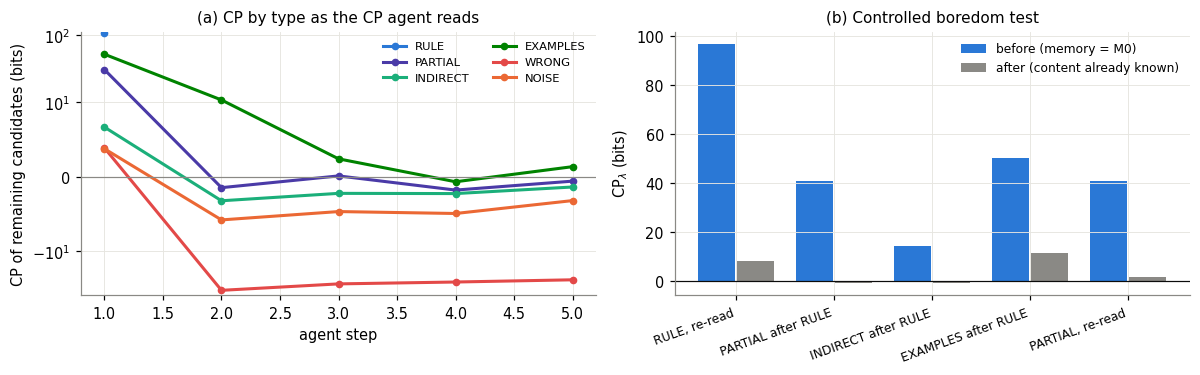

✔ SUPPORTED   Re-reading an assimilated regularity yields (near-)zero progress
      CP of RULE: before 97.0 bits → after 8.1 bits; PARTIAL after RULE: 40.9 → -0.9


In [ ]:
# ---- 3.11  E3 ----
pairs = [("RULE", M0, M0 + ("RULE",), "RULE, re-read"), ("PARTIAL_1", M0, M0 + ("RULE",), "PARTIAL after RULE"),
         ("INDIRECT", M0, M0 + ("RULE",), "INDIRECT after RULE"), ("EXAMPLES", M0, M0 + ("RULE",), "EXAMPLES after RULE"),
         ("PARTIAL_1", M0, M0 + ("PARTIAL_1",), "PARTIAL, re-read")]
bb = []
for wid in sorted(TEST):
    we = EVALS[wid]
    for key, m_before, m_after, lab in pairs:
        b_, a_ = we.terms(m_before, key), we.terms(m_after, key)
        bb.append(dict(world=wid, label=lab, before=b_["G_seal"] - LAM * b_["S"], after=a_["G_seal"] - LAM * a_["S"],
                       G_before=b_["G_seal"], G_after=a_["G_seal"]))
BB = pd.DataFrame(bb)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
if len(BOR):
    for t, col in [("RULE", PAL["blue"]), ("PARTIAL", PAL["violet"]), ("INDIRECT", PAL["aqua"]), ("EXAMPLES", PAL["green"]),
                   ("WRONG", PAL["red"]), ("NOISE", PAL["orange"])]:
        g = BOR[BOR.type == t].groupby("step").CP.mean()
        if len(g): ax[0].plot(g.index, g.values, marker="o", ms=4, color=col, label=t)
    ax[0].axhline(0, color=PAL["grey"], lw=0.8); ax[0].set_yscale("symlog", linthresh=10)
    ax[0].set(xlabel="agent step", ylabel="CP of remaining candidates (bits)", title="(a) CP by type as the CP agent reads")
    ax[0].legend(fontsize=7.5, ncol=2)
labs = [p[3] for p in pairs]; x = np.arange(len(labs))
mb = BB.groupby("label").before.mean().reindex(labs); ma = BB.groupby("label").after.mean().reindex(labs)
ax[1].bar(x - 0.2, mb.values, 0.38, color=PAL["blue"], label="before (memory = M0)")
ax[1].bar(x + 0.2, ma.values, 0.38, color=PAL["grey"], label="after (content already known)")
ax[1].axhline(0, color="#0b0b0b", lw=0.8); ax[1].set_xticks(x); ax[1].set_xticklabels(labs, rotation=20, ha="right", fontsize=8)
ax[1].set(ylabel="CP$_\\lambda$ (bits)", title="(b) Controlled boredom test"); ax[1].legend(fontsize=8)
savefig(fig, "fig6_e3_boredom")
bt = BB.groupby("label").agg(before=("before", "mean"), after=("after", "mean")).reindex(labs)
bt.index.name = "Document"; to_latex(bt, "e3_boredom", "E3: CP$_\\lambda$ (bits) of a document before vs after its content is in memory.", "{:.1f}")
RESULTS["E3"] = bt.to_dict()
reread = BB[BB.label == "RULE, re-read"]
claim("E3_boredom", "Re-reading an assimilated regularity yields (near-)zero progress",
      reread.after.mean() < 0.2 * max(reread.before.mean(), 1e-9) and reread.before.mean() > 0,
      f"CP of RULE: before {reread.before.mean():.1f} bits → after {reread.after.mean():.1f} bits; "
      f"PARTIAL after RULE: {BB[BB.label=='PARTIAL after RULE'].before.mean():.1f} → {BB[BB.label=='PARTIAL after RULE'].after.mean():.1f}")

## E5 — Interestingness is observer-relative (§2.11): model size and education
**E5a.** The same worlds are scored by observers of different capacity. If interestingness is subjective, each observer's CP should predict *its own* utility better than another observer's utility, and capability-demanding documents (`INDIRECT`) should matter more to bigger observers.

**E5b (Schönberg test).** `ADVANCED` maps suffixes to named patterns, which are meaningless without the `PRIMER` that defines them. Prediction: `ADVANCED` has ~zero CP for an uneducated observer and large CP once the primer is in memory.

In [ ]:
# ---- 3.12  E5: observer blocks ----
OBS_WORLDS = sorted(TEST)[:CFG["n_worlds_observer"]]
def short(name): return name.split("/")[-1].replace("-Instruct", "")
def education_rows(we, obs):
    rows = []
    for cand, mem, cond in [("ADVANCED", M0, "without primer"), ("ADVANCED", M0 + ("PRIMER",), "with primer"),
                            ("PRIMER", M0, "without advanced"), ("PRIMER", M0 + ("ADVANCED",), "with advanced")]:
        t = we.terms(mem, cand)
        rows.append(dict(observer=obs, world=we.w.seed, doc=cand, cond=cond, G_seal=t["G_seal"], S=t["S"], CP=t["G_seal"] - LAM * t["S"], U=t["U"]))
    return rows
def observer_block(scorer, evals=None):
    e1, edu = [], []
    for wid in OBS_WORLDS:
        we = evals[wid] if evals is not None else WorldEval(World(wid), scorer)
        e1.append(add_cp(signals_for(we, M0, E1_KEYS, use_judge=False, rng=np.random.default_rng(wid), unsealed=False), LAM))
        edu += education_rows(we, short(scorer.name))
    return pd.concat(e1, ignore_index=True), pd.DataFrame(edu)
OBS = {}
t0 = time.time()
OBS[short(CFG["main_model"])] = observer_block(SC, EVALS)
print(f"  observer {short(CFG['main_model'])} done ({time.time()-t0:.0f}s)")
SC.close(); del EVALS; gc.collect()
obs_list = list(CFG["observers"])
if MODE == "FULL":                      # add a 7B observer when the GPU has room for it (about 16 GB of weights)
    try:
        import torch
        if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory > 22e9:
            obs_list.append("Qwen/Qwen2.5-7B-Instruct")
    except Exception as e: print("  7B observer check failed:", e)
if short(CFG["main_model"]) not in [short(n) for n in obs_list]: obs_list.append(CFG["main_model"])
for name in obs_list:
    if short(name) in OBS: continue
    try:
        sc = load_scorer(name, max_batch_tokens=6000 if "7B" in name else None)
        OBS[short(name)] = observer_block(sc); sc.close(); del sc
        print(f"  observer {short(name)} done ({time.time()-t0:.0f}s)")
    except Exception as e:              # e.g. out of memory: report and carry on with the observers that ran
        print(f"  observer {short(name)} skipped: {type(e).__name__}: {str(e)[:120]}")
    gc.collect()
    try:
        import torch; torch.cuda.empty_cache()
    except Exception: pass
OBS_NAMES = [short(n) for n in obs_list if short(n) in OBS]

  observer Qwen2.5-1.5B done (8s)


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (23 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

  loaded Qwen/Qwen2.5-7B-Instruct on cuda (torch.bfloat16)
  observer Qwen2.5-7B done (297s)


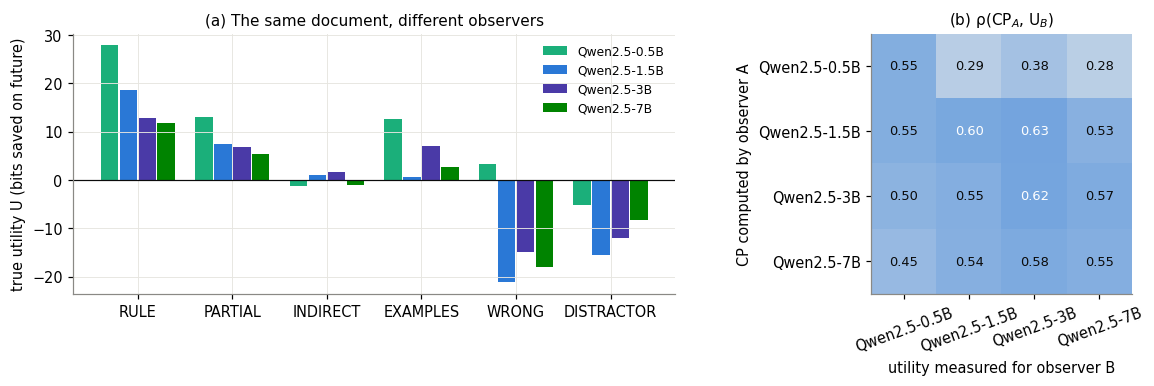

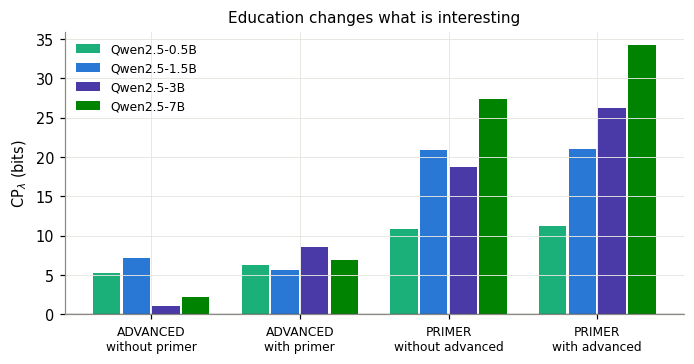

✔ SUPPORTED   Each observer's compression progress predicts its own utility at least as well as other observers' utility
      mean ρ(CP_A, U_A)=0.579 vs ρ(CP_A, U_B≠A)=0.486
✘ NOT SUPPORTED   Capability-demanding explanations (INDIRECT) are worth relatively more to larger observers
      U(INDIRECT)/U(RULE): Qwen2.5-0.5B=-0.05, Qwen2.5-1.5B=0.06, Qwen2.5-3B=0.14, Qwen2.5-7B=-0.08
✔ SUPPORTED   For the most capable observer, the advanced note becomes interesting only after the primer is known (the Schönberg effect)
      CP(ADVANCED) without → with primer: Qwen2.5-0.5B: 5.3 → 6.3 bits (p=0.33); Qwen2.5-1.5B: 7.1 → 5.7 bits (p=0.56); Qwen2.5-3B: 1.1 → 8.6 bits (p=0.00024); Qwen2.5-7B: 2.2 → 6.8 bits (p=0.0087)


In [ ]:
# ---- 3.13  E5 analysis + Figures 8, 9 ----
k = len(OBS_NAMES); XM = np.zeros((k, k))
for i, a in enumerate(OBS_NAMES):
    for j, b in enumerate(OBS_NAMES):
        A, B = OBS[a][0].set_index(["world", "key"]), OBS[b][0].set_index(["world", "key"])
        XM[i, j] = np.mean([stats.spearmanr(A.loc[wid].CP, B.loc[wid].loc[A.loc[wid].index].U).correlation for wid in OBS_WORLDS])
diag, off = np.mean(np.diag(XM)), (XM.sum() - np.trace(XM)) / max(1, k * k - k)
TYPES5 = ["RULE", "PARTIAL", "INDIRECT", "EXAMPLES", "WRONG", "DISTRACTOR"]
per_type = pd.DataFrame({o: OBS[o][0].groupby("type").U.mean().reindex(TYPES5) for o in OBS_NAMES})
def _rel(o):   # value of the indirect explanation relative to the explicit one (undefined if the explicit one is worthless)
    ur = OBS[o][0].query("type=='RULE'").U.mean(); return OBS[o][0].query("type=='INDIRECT'").U.mean() / ur if ur > 1 else np.nan
rel_ind = {o: _rel(o) for o in OBS_NAMES}
EDU = pd.concat([OBS[o][1] for o in OBS_NAMES], ignore_index=True)

obs_cols = [PAL["aqua"], PAL["blue"], PAL["violet"], PAL["green"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
wdt = 0.8 / k; x = np.arange(len(TYPES5))
for i, o in enumerate(OBS_NAMES):
    ax[0].bar(x + (i - (k - 1) / 2) * wdt, per_type[o].values, wdt * 0.92, color=obs_cols[i % 4], label=o)
ax[0].axhline(0, color="#0b0b0b", lw=0.8); ax[0].set_xticks(x); ax[0].set_xticklabels(TYPES5)
ax[0].set(ylabel="true utility U (bits saved on future)", title="(a) The same document, different observers"); ax[0].legend(fontsize=8)
im = ax[1].imshow(XM, cmap=LinearSegmentedColormap.from_list("seq", ["#f1f0ec", PAL["blue"]]), vmin=min(0, XM.min()), vmax=1)
ax[1].set_xticks(range(k)); ax[1].set_xticklabels(OBS_NAMES, rotation=20); ax[1].set_yticks(range(k)); ax[1].set_yticklabels(OBS_NAMES)
ax[1].set(xlabel="utility measured for observer B", ylabel="CP computed by observer A", title="(b) ρ(CP$_A$, U$_B$)"); ax[1].grid(False)
for (r, c), v in np.ndenumerate(XM): ax[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > 0.6 else "#0b0b0b")
savefig(fig, "fig8_e5_observers")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
conds = [("ADVANCED", "without primer"), ("ADVANCED", "with primer"), ("PRIMER", "without advanced"), ("PRIMER", "with advanced")]
x = np.arange(len(conds))
for i, o in enumerate(OBS_NAMES):
    e = EDU[EDU.observer == o]; vals = [e[(e.doc == d) & (e.cond == c)].CP.mean() for d, c in conds]
    ax.bar(x + (i - (k - 1) / 2) * wdt, vals, wdt * 0.92, color=obs_cols[i % 4], label=o)
ax.axhline(0, color="#0b0b0b", lw=0.8); ax.set_xticks(x); ax.set_xticklabels([f"{d}\n{c}" for d, c in conds], fontsize=8)
ax.set(ylabel="CP$_\\lambda$ (bits)", title="Education changes what is interesting"); ax.legend(fontsize=8)
savefig(fig, "fig9_e5b_education")

edu_tab = EDU.groupby(["observer", "doc", "cond"]).agg(CP=("CP", "mean"), G_seal=("G_seal", "mean"), U=("U", "mean")).round(1)
edu_tab.index = [" / ".join(i) for i in edu_tab.index]; edu_tab.index.name = "observer / document / memory"
to_latex(edu_tab, "e5b_education", "E5b: CP$_\\lambda$, sealed gain and true utility (bits) of the ADVANCED and PRIMER documents with and without the other in memory.", "{:.1f}")
xm = pd.DataFrame(XM, index=OBS_NAMES, columns=OBS_NAMES); xm.index.name = "CP from \\ U for"
to_latex(xm, "e5_cross_observer", "E5a: mean Spearman correlation between observer A's CP and observer B's true utility.", "{:.2f}")
RESULTS["E5"] = dict(cross=XM.tolist(), observers=OBS_NAMES, diag=diag, off=off, per_type_U=per_type.to_dict(), rel_indirect=rel_ind,
                     education=edu_tab.to_dict())
claim("E5_subjective", "Each observer's compression progress predicts its own utility at least as well as other observers' utility",
      diag >= off, f"mean ρ(CP_A, U_A)={diag:.3f} vs ρ(CP_A, U_B≠A)={off:.3f}")
sizes = OBS_NAMES
claim("E5_capability", "Capability-demanding explanations (INDIRECT) are worth relatively more to larger observers",
      bool(np.isfinite(rel_ind[sizes[-1]]) and np.isfinite(rel_ind[sizes[0]]) and rel_ind[sizes[-1]] > rel_ind[sizes[0]] + 0.05),
      "U(INDIRECT)/U(RULE): " + ", ".join(f"{o}={rel_ind[o]:.2f}" for o in sizes))
ed_ok, ed_txt = None, []
for o in OBS_NAMES:
    e = EDU[(EDU.observer == o) & (EDU.doc == "ADVANCED")].pivot(index="world", columns="cond", values="CP")
    p_ = wilcoxon_p(e["with primer"], e["without primer"])
    ed_ok = e["with primer"].mean() > e["without primer"].mean() + 1 and p_ < 0.05   # last iteration = most capable observer
    ed_txt.append(f"{o}: {e['without primer'].mean():.1f} → {e['with primer'].mean():.1f} bits (p={p_:.2g})")
claim("E5_education", "For the most capable observer, the advanced note becomes interesting only after the primer is known (the Schönberg effect)", ed_ok,
      "CP(ADVANCED) without → with primer: " + "; ".join(ed_txt))

## E6 — Weight-level compression progress (optional, GPU)
The same quantity, with the compressor changed by **learning** instead of by context: we fine-tune a LoRA adapter on the document alone, then re-score the sealed audit *without* the document in context. $G_w=L_{\theta}(h_{\text{aud}}\mid M_0,h_{\text{exp}})-L_{\theta+\Delta_D}(h_{\text{aud}}\mid M_0,h_{\text{exp}})$. This is Schmidhuber's original setting: reward the change in the compressor's parameters. Does it agree with the cheap in-context version?

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  loaded Qwen/Qwen2.5-0.5B-Instruct on cuda (torch.float32)
  E6 world 14 (122s)
  E6 world 15 (246s)
  E6 world 16 (369s)
  E6 world 17 (493s)
  E6 world 18 (616s)
  E6 world 19 (739s)
  E6 world 20 (853s)
  E6 world 21 (978s)
         median G_w (bits)  ρ(G_ic, G_w)  ρ(G_w, U_w)
LoRA lr                                              
0.00003              4.027         0.382        0.228
0.00010            -16.167        -0.224        0.425
0.00030           -181.396        -0.283        0.857 
selected lr (label-free, world 14 ): 3e-05


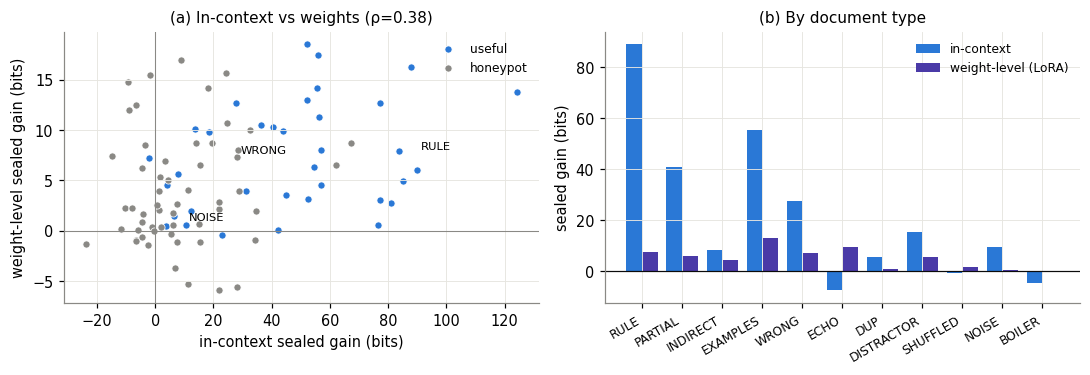

✔ SUPPORTED   Weight-level sealed gain agrees with the in-context sealed gain
      lr=3e-05 (chosen label-free): mean per-world Spearman(G in-context, G weight)=0.38 (CP incl. shared cost term: 0.38); ρ(weight CP, weight utility)=0.23


In [ ]:
# ---- 3.14  E6 ----
E6 = None
if CFG["run_weight_level"] and MODE != "TEST":
    import torch
    import peft.import_utils, peft.tuners.lora.torchao as _pt
    # Colab ships an old torchao that makes recent peft raise ImportError while building LoRA layers. We never use torchao,
    # so tell peft it is absent (works without restarting the runtime).
    peft.import_utils.is_torchao_available = _pt.is_torchao_available = lambda: False
    from peft import LoraConfig, get_peft_model
    WS = HFScorer(CFG["weight_model"], max_batch_tokens=CFG["max_batch_tokens"], dtype=torch.float32)
    WS.model = get_peft_model(WS.model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, task_type="CAUSAL_LM",
                              target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    lora_init = {k_: v.detach().clone() for k_, v in WS.model.state_dict().items() if "lora_" in k_}
    W6_DOCS = ["RULE", "PARTIAL_1", "PARTIAL_2", "INDIRECT", "EXAMPLES", "WRONG_1", "WRONG_2", "ECHO_1", "DUP",
               "DISTRACTOR_1", "SHUFFLED_1", "NOISE_1", "BOILER_1"]
    # A first run with lr=1e-3 x 30 steps damaged the model on every document (all gains -500..-2000 bits), so we sweep gentler
    # settings. The learning rate is chosen WITHOUT labels on the first world (highest median weight-level gain over all
    # documents, i.e. 'learns without breaking'), and results are reported on the remaining worlds.
    N_STEPS, LRS = 10, [3e-5, 1e-4, 3e-4]
    def audit_bits(we):
        r = WS.score([we.seq(M0, None)])[0]
        return sum(v["bits"] for k_, v in r.items() if k_[0] == "a"), sum(v["bits"] for k_, v in r.items() if k_[0] == "q")
    def reset():
        r_ = WS.model.load_state_dict(lora_init, strict=False); assert not r_.unexpected_keys; WS.model.eval()
    e6 = []; t0 = time.time()
    for wid in sorted(TEST)[:CFG["n_worlds_weight"]]:
        reset(); we = WorldEval(World(wid), WS); a0, q0 = audit_bits(we)
        for d in W6_DOCS:
            reset(); t = we.terms(M0, d)                     # in-context version, scored with the untouched base model
            ids = WS.ids(HEADER) + WS.ids(we.docs[d])
            for lr in LRS:
                reset(); WS.model.train()
                opt = torch.optim.AdamW([p_ for p_ in WS.model.parameters() if p_.requires_grad], lr=lr)
                for _ in range(N_STEPS):
                    lp = WS._token_logprobs([ids], [list(range(len(WS.ids(HEADER)), len(ids)))], grad=True)
                    loss = -lp.mean(); opt.zero_grad(); loss.backward(); opt.step()
                WS.model.eval(); a1, q1 = audit_bits(we)
                e6.append(dict(world=wid, key=d, lr=lr, type=dtype_of(d), useful=dtype_of(d) in USEFUL_TYPES, S=t["S"],
                               G_ic=t["G_seal"], U_ic=t["U"], G_w=a0 - a1, U_w=q0 - q1))
        reset(); print(f"  E6 world {wid} ({time.time()-t0:.0f}s)")
    WS.close(); del WS; gc.collect()
    E6ALL = pd.DataFrame(e6)
    E6ALL["CP_ic"], E6ALL["CP_w"] = E6ALL.G_ic - LAM * E6ALL.S, E6ALL.G_w - LAM * E6ALL.S
    sel_world = E6ALL.world.min()
    LR_SEL = E6ALL[E6ALL.world == sel_world].groupby("lr").G_w.median().idxmax()
    lr_tab = E6ALL[E6ALL.world != sel_world].groupby("lr").apply(lambda d: pd.Series({
        "median G_w (bits)": d.G_w.median(), "ρ(G_ic, G_w)": d.groupby("world").apply(lambda g: stats.spearmanr(g.G_ic, g.G_w).correlation).mean(),
        "ρ(G_w, U_w)": d.groupby("world").apply(lambda g: stats.spearmanr(g.G_w, g.U_w).correlation).mean()}))
    lr_tab.index.name = "LoRA lr"; print(lr_tab.round(3).to_string(), "\nselected lr (label-free, world", sel_world, "):", LR_SEL)
    to_latex(lr_tab, "e6_lr_sweep", f"E6 learning-rate sweep ({N_STEPS} LoRA steps), evaluated on worlds other than the selection world.", "{:.2f}")
    E6 = E6ALL[(E6ALL.lr == LR_SEL) & (E6ALL.world != sel_world)].copy()
    if E6.empty: E6 = E6ALL[E6ALL.lr == LR_SEL].copy()
    # compare the GAINS: CP_ic and CP_w share the same -λS term, which would inflate their agreement
    r_icw = E6.groupby("world").apply(lambda g: stats.spearmanr(g.G_ic, g.G_w).correlation).mean()
    r_icw_cp = E6.groupby("world").apply(lambda g: stats.spearmanr(g.CP_ic, g.CP_w).correlation).mean()
    r_wU = E6.groupby("world").apply(lambda g: stats.spearmanr(g.CP_w, g.U_w).correlation).mean()
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for use, col, lab in [(True, PAL["blue"], "useful"), (False, PAL["grey"], "honeypot")]:
        d = E6[E6.useful == use]
        ax[0].scatter(d.G_ic, d.G_w, s=22, color=col, label=lab, edgecolor="white", linewidth=0.5)
    for t_ in ["RULE", "WRONG", "NOISE"]:
        d = E6[E6.type == t_]
        if len(d): ax[0].annotate(t_, (d.G_ic.mean(), d.G_w.mean()), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
    ax[0].axhline(0, color=PAL["grey"], lw=0.7); ax[0].axvline(0, color=PAL["grey"], lw=0.7)
    ax[0].set(xlabel="in-context sealed gain (bits)", ylabel="weight-level sealed gain (bits)", title=f"(a) In-context vs weights (ρ={r_icw:.2f})")
    ax[0].legend(fontsize=8)
    gt = E6.groupby("type")[["G_ic", "G_w"]].mean().reindex([t_ for t_ in TYPE_ORDER if t_ in set(E6.type)])
    xx = np.arange(len(gt)); ax[1].bar(xx - 0.2, gt.G_ic, 0.38, color=PAL["blue"], label="in-context")
    ax[1].bar(xx + 0.2, gt.G_w, 0.38, color=PAL["violet"], label="weight-level (LoRA)")
    ax[1].axhline(0, color="#0b0b0b", lw=0.8); ax[1].set_xticks(xx); ax[1].set_xticklabels(gt.index, rotation=30, ha="right", fontsize=8)
    ax[1].set(ylabel="sealed gain (bits)", title="(b) By document type"); ax[1].legend(fontsize=8)
    savefig(fig, "fig10_e6_weight_level")
    t6 = gt.copy(); t6.index.name = "Document type"
    to_latex(t6, "e6_weight_level", f"E6: sealed gain (bits) in context vs after LoRA fine-tuning on the document ({short(CFG['weight_model'])}, {N_STEPS} steps, lr={LR_SEL}).", "{:.1f}")
    RESULTS["E6"] = dict(lr_selected=LR_SEL, lr_sweep=lr_tab.to_dict(), rho_gain_ic_vs_weight=r_icw, rho_cp_ic_vs_weight=r_icw_cp, rho_weightCP_vs_weightU=r_wU, by_type=gt.to_dict())
    claim("E6_weights", "Weight-level sealed gain agrees with the in-context sealed gain", r_icw > 0.3,
          f"lr={LR_SEL} (chosen label-free): mean per-world Spearman(G in-context, G weight)={r_icw:.2f} (CP incl. shared cost term: {r_icw_cp:.2f}); ρ(weight CP, weight utility)={r_wU:.2f}")
else:
    print("E6 skipped (enable run_weight_level on a GPU runtime).")

---
# Part 4 — Report: everything the paper needs
Writes `paper_inputs/` (every number, table and figure the LaTeX paper prints, plus `prose_checks.txt`), `results.json`, `paper_summary.md` (headline numbers and a claim-by-claim verdict), every figure as PDF and PNG, and every table as LaTeX and CSV. It then zips the folder for download.

**To update the paper:** unzip, copy the `paper_inputs` folder next to `main.tex` (replacing the old one) and recompile. Read `prose_checks.txt` first: each line is a statement the paper's text makes, tested against this run.

In [ ]:
# ---- 4.0  Paper inputs: every number and table the LaTeX paper prints ----
# The paper never contains a hand-typed result. It \input's paper_inputs/numbers.tex (one \setnum{key}{value} per number)
# and paper_inputs/tab_*.tex. Copy the whole paper_inputs folder next to main.tex and recompile.
PIN = os.path.join(RESULTS_DIR, "paper_inputs"); os.makedirs(PIN, exist_ok=True)
MINUS = "\\ensuremath{-}"
def _f(x, d=2, plus=False):
    if x is None or not np.isfinite(x): return "n/a"
    s = f"{abs(x):.{d}f}"; neg = x < 0 and float(s) != 0
    return (MINUS if neg else ("+" if plus else "")) + s
def _pct(x): return "n/a" if x is None or not np.isfinite(x) else f"{100 * x:.0f}\\%"
def _p(p):
    if p is None or not np.isfinite(p): return "n/a"
    if p >= 0.001: return f"{p:.3f}"
    m, e = f"{p:.1e}".split("e"); return f"\\ensuremath{{{m}\\times 10^{{{int(e)}}}}}"
def _ci(t, d=2): return f"{_f(t[0], d)} [{_f(t[1], d)}, {_f(t[2], d)}]"
CP_NAME = "sealed gain" if LAM == 0 else f"CP at $\\lambda={LAM:g}$"
PROSE = {"CP": CP_NAME, "CP_ratio": "gain per bit read", "IG_full": "unsealed gain", "surprise": "surprise", "low_ppl": "low perplexity",
         "novelty": "embedding novelty", "relevance": "embedding relevance", "judge": "the LLM judge", "random": "random choice", "oracle": "the oracle"}
DAG = "\\,$^\\dagger$"      # marks our signals in Table 1
ROW = {"CP": ("Sealed gain $G$" if LAM == 0 else f"$\\mathrm{{CP}}_{{{LAM:g}}}$") + DAG, "CP_ratio": "Gain per bit $G/S$" + DAG,
       "IG_full": "Unsealed gain", "surprise": "Surprise", "low_ppl": "Low perplexity", "novelty": "Emb. novelty",
       "relevance": "Emb. relevance", "judge": "LLM judge", "random": "Random", "oracle": "Oracle"}
NUM, CHECKS = {}, []
def check(ok, claim, where): CHECKS.append((bool(ok), claim, where))   # claim = what the paper's text says; where = the passage that says it

# --- configuration
NUM.update({"cfg.nworlds": len(WORLDS), "cfg.ndev": len(DEV), "cfg.ntest": len(TEST), "cfg.nagent": len(AGENT_WORLDS),
            "cfg.nobs": len(OBS_WORLDS), "cfg.lam": f"{LAM:g}", "cfg.steps": CFG["agent_steps"], "cfg.budgetx": f"{CFG['agent_budget_x']:g}",
            "cfg.budget": f"{np.mean(list(BUDGET.values())):.0f}",
            "cfg.nlong": N_LONG,
            "dev.rho.lam0": _f(lam_scores[0.0]), "dev.rho.maxpos": _f(max(v for l, v in lam_scores.items() if l > 0)), "dev.rho.lam1": _f(lam_scores[1.0])})
check(LAM == 0,
      "the dev worlds select lambda = 0, so the ranked signal is sealed gain G (this run selected lambda = " + f"{LAM:g})", "Statistics paragraph, and every place that calls the ranking signal sealed gain")

# --- exact coders (Part 1 and 2)
tc = summ.loc["teachable w=8"]; echo = coh.loc["ECHO (copy of h_exp)"]; egci = boot_ci(g_prior)
_coh = toy_props.query("coder=='coherent'"); _cohdiff = max((_coh.CP1_full - _coh.CP1_seal).abs().max(), 1e-99)
NUM.update({"toy.pairs": f"{int((toy_props.coder == 'coherent').sum()):,}".replace(",", "{,}"), "toy.maxcp": _f(max_cp1_coh, 2),
            "toy.teach": _pct(tc.frac_CP1_seal_pos.max()), "toy.teachother": _pct(tc.frac_CP1_seal_pos.drop(tc.frac_CP1_seal_pos.idxmax()).max()),
            "toy.cohdiff": _p(float(_cohdiff)), "toy.eg": _f(egci[0], 2), "toy.eglo": _f(egci[1], 2), "toy.eghi": _f(egci[2], 2),
            "toy.ndraws": len(g_prior), "toy.echofull": _f(echo.G_full, 1), "toy.echoseal": _f(echo.G_seal, 1),
            "toy.mixed": _pct(mixed_pos), "toy.seeds": CFG["toy_seeds"], "toy.steps": CFG["toy_steps"],
            "toy.noise.surprise": _pct(noise_share["surprise"][0]), "toy.noise.infogain": _pct(noise_share["infogain"][0]),
            "toy.noise.cp": _pct(noise_share["cp"][0]), "toy.noise.retro": _pct(noise_share["cp_retro"][0]),
            "toy.err.cp": _f(final["cp"][0], 2), "toy.err.random": _f(final["random"][0], 2), "toy.err.novelty": _f(final["novelty"][0], 2),
            "toy.err.surprise": _f(final["surprise"][0], 2), "toy.p.random": _p(wilcoxon_p(cp_err, rnd_err)),
            "toy.u.early": U_STEPS[0], "toy.u.new": _pct(cp_early[2]), "toy.u.known": _pct(cp_early[0]), "toy.u.noise": _pct(cp_early[-1]),
            "toy.u.surpnoise": _pct(sur_full[-1])})
check(max_cp1_coh <= 1e-6,
      "the coherent coder never produces CP_1 > 0", "Section 4, paragraph 2")
check("RULE" in tc.frac_CP1_seal_pos.idxmax(),
      "the teachable coder crosses zero most often for the compact rule", "Section 4, paragraph 2")
check(_cohdiff < 1e-6,
      "for the coherent coder the sealed and unsealed forms of CP_1 agree", "Section 4, paragraph 2")
check(int(np.argmax(cp_early)) == 2,
      "compression progress puts most early steps on the new but regular channel", "Section 4, last paragraph")
for k_ in ("P2", "P5c", "P6", "toy_noisy_tv", "toy_sealing", "toy_vs_random", "toy_learning", "toy_inverted_u"):
    check(RESULTS["claims"][k_]["supported"],
          f"notebook claim {k_}: " + RESULTS["claims"][k_]["statement"], "Section 4")

# --- E1 ranking
p_e1 = wilcoxon_p(met["CP"].rho.values, met[best_base].rho.values)
w3 = max(baselines, key=lambda s: met[s].wrong_at_k.mean())
NUM.update({"e1.rho.CP": _f(met["CP"].rho.mean()), "e1.rho.best": _f(met[best_base].rho.mean()), "e1.best": PROSE[best_base], "e1.p": _p(p_e1),
            "e1.dacc.CP": _f(met["CP"].top1_dacc.mean(), 3, plus=True), "e1.dacc.oracle": _f(met["oracle"].top1_dacc.mean(), 3, plus=True),
            "e1.honey.CP": _pct(met["CP"].honey_at_k.mean()), "e1.wrongbelow": _pct(wrong_vs_rule),
            "e1.wrong3.maxname": PROSE[w3], "e1.wrong3.max": _pct(met[w3].wrong_at_k.mean())})
for k_ in ("E1_ranking", "E1_honeypots", "E1_wrong"):
    check(RESULTS["claims"][k_]["supported"],
          f"notebook claim {k_}: " + RESULTS["claims"][k_]["statement"], "Sealed gain ranks by true value, the abstract and the conclusion")
check(H.loc["NOISE", "surprise"] >= H["surprise"].max() - 1e-9 and H.loc["NOISE", "novelty"] >= H["novelty"].max() - 1e-9,
      "surprise and novelty score noise highest", "paragraph on Figure 3")
check(H.loc["ECHO", "IG_full"] >= H.loc["RULE", "IG_full"] - 0.2,
      "unsealed gain rates echoes as highly as the true guide (within 0.2 z)", "paragraph on Figure 3")
check(min(H.loc["WRONG", "relevance"], H.loc["DISTRACTOR", "relevance"]) >= H.loc["RULE", "relevance"] - 0.2,
      "relevance scores wrong guides and guides to other worlds as highly as the true guide (within 0.2 z)", "paragraph on Figure 3")
if "judge" in H.columns:
    check(max(H.loc["SHUFFLED", "judge"], H.loc["DUP", "judge"]) > H.loc["RULE", "judge"],
          "the judge prefers shuffled or duplicated text to the true guide", "paragraph on Figure 3")
else: check(False, "the judge was run", "paragraph on Figure 3 and Table 1 (judge disabled in this run)")
check(met["CP"].top1_dacc.mean() > max(met[s].top1_dacc.mean() for s in baselines),
      "reading sealed gain's top document raises future attribute accuracy more than any baseline's top document", "Section 6, 'The ground truth is circular'")
rows = []
for s in sorted([s for s in SIGNALS if s != "oracle"], key=lambda s: -met[s].rho.mean()) + ["oracle"]:
    m = met[s]
    rows.append(("\\midrule\n" if s == "oracle" else "") + f"{ROW[s]} & {_f(m.rho.mean()) if s == 'oracle' else _ci(boot_ci(m.rho))} & "
                f"{_f(m.top1_dacc.mean(), 3, plus=True)} & {_f(m.honey_at_k.mean())} \\\\")
with open(os.path.join(PIN, "tab_e1.tex"), "w") as f:
    f.write("\\begin{tabular}{@{}lccc@{}}\n\\toprule\nSignal & $\\rho$ [95\\% CI] & Acc. & Distr. \\\\\n\\midrule\n" + "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}\n")

# --- E4 dose-response
kmax = KS[-1]; db = max([s for s in E4_SIGS if s not in ("CP", "CP_ratio")], key=lambda s: dose[s][kmax].mean())
NUM.update({"dose.k": kmax, "dose.CP": _pct(dose["CP"][kmax].mean()), "dose.maxbase": _pct(dose[db][kmax].mean()), "dose.maxbasename": PROSE[db]})
check(dose["CP"][kmax].mean() > dose[db][kmax].mean(), "sealed gain finds the single useful document more often than every baseline", "dose-response sentence, and the abstract")

# --- E2 / E2b agents, E3 boredom
p_ag = wilcoxon_p(fin.loc["CP"].q_bpt.values, fin.loc[best_bits].q_bpt.values)
p_ag_acc = wilcoxon_p(fin.loc["CP"].q_acc.values, fin.loc[best_bits].q_acc.values)
NUM.update({"ag.acc.CP": _f(fin.loc["CP"].q_acc.mean()), "ag.bpt.CP": _f(fin.loc["CP"].q_bpt.mean(), 3),
            "ag.best": PROSE[best_bits], "ag.acc.best": _f(fin.loc[best_bits].q_acc.mean()), "ag.bpt.best": _f(fin.loc[best_bits].q_bpt.mean(), 3),
            "ag.p.bpt": _p(p_ag), "ag.p.acc": _p(p_ag_acc), "ag.acc.ratio": _f(fin.loc["CP_ratio"].q_acc.mean()), "ag.bpt.ratio": _f(fin.loc["CP_ratio"].q_bpt.mean(), 3),
            "ag.tok.ratio": f"{fin.loc['CP_ratio'].tokens.mean():.0f}", "ag.tok.CP": f"{fin.loc['CP'].tokens.mean():.0f}",
            "ag.acc.start": _f(AG[(AG.strat == "CP") & (AG.step == 0)].q_acc.mean()),
            "agb.bpt.ratio": _f(finb.loc["CP_ratio"].q_bpt.mean(), 3), "agb.bpt.CP": _f(finb.loc["CP"].q_bpt.mean(), 3),
            "agb.best": PROSE[bestb_b], "agb.bpt.best": _f(finb.loc[bestb_b].q_bpt.mean(), 3), "agb.p": _p(pb_b)})
check(fin.loc["CP"].q_bpt.mean() <= fin.loc[best_bits].q_bpt.mean(),
      "the sealed-gain agent has the lowest bits per token of the non-oracle agents after a fixed number of reads", "A curious agent")
check(not (np.isfinite(pb_b) and pb_b < 0.05), "under the token budget the ratio agent's margin over the best baseline is not significant", "A curious agent, token-budget sentences")
_others = [s for s in nonor_b if s != "IG_full"]
check(bestb_b == "IG_full" and max(finb.loc[s].q_bpt.mean() for s in ("CP", "CP_ratio", "IG_full")) + 0.02 < min(finb.loc[s].q_bpt.mean() for s in _others),
      "under the token budget the three gain-based signals (ratio, sealed gain, unsealed gain) are within a hair of each other and clearly ahead of the other baselines",
      "A curious agent, token-budget sentences")
rows = []
for s in sorted([s for s in AGENT_STRATS if s != "oracle"], key=lambda s: fin.loc[s].q_bpt.mean()) + ["oracle"]:
    a, b = fin.loc[s], finb.loc[s]
    rows.append(("\\midrule\n" if s == "oracle" else "") + f"{ROW[s].replace(DAG, '')} & {_f(a.q_acc.mean())} & {_f(a.q_bpt.mean(), 3)} & {a.tokens.mean():.0f} & "
                f"{_f(b.q_acc.mean())} & {_f(b.q_bpt.mean(), 3)} & {b.tokens.mean():.0f} \\\\")
with open(os.path.join(PIN, "tab_agent.tex"), "w") as f:
    f.write("\\begin{tabular}{@{}lcccccc@{}}\n\\toprule\n & \\multicolumn{3}{c}{" + f"{CFG['agent_steps']} reads" + "} & \\multicolumn{3}{c}{" +
            f"Budget {CFG['agent_budget_x']:g}$\\times$" + "} \\\\\n\\cmidrule(lr){2-4}\\cmidrule(l){5-7}\nSignal & Acc. & b/t & Tok. & Acc. & b/t & Tok. \\\\\n\\midrule\n" +
            "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}\n")
bg = BB.groupby("label")[["G_before", "G_after"]].mean()
NUM.update({"bore.rule.before": _f(bg.loc["RULE, re-read", "G_before"], 1), "bore.rule.after": _f(bg.loc["RULE, re-read", "G_after"], 1),
            "bore.partial.before": _f(bg.loc["PARTIAL after RULE", "G_before"], 1), "bore.partial.after": _f(bg.loc["PARTIAL after RULE", "G_after"], 1)})
check(bg.loc["PARTIAL after RULE", "G_after"] < 0.5 * bg.loc["PARTIAL after RULE", "G_before"], "a partial guide loses most of its sealed gain once the full guide is in memory", "Boredom paragraph")
check(RESULTS["claims"]["E3_boredom"]["supported"],
      "notebook claim E3_boredom: " + RESULTS["claims"]["E3_boredom"]["statement"], "Boredom paragraph, the abstract and the conclusion")

# --- E8 / E9 ablations
def _echo_rank(df, sig): return df.groupby("world").apply(lambda g: (g[sig].rank(ascending=False)[g.type == "ECHO"]).mean()).mean()
abl = [("\\emph{Cost weight} $\\lambda$", None, None)]
for lam in [l for l in (0.0, 0.1, 0.5, 1.0) if l in CFG["lambdas"]]:
    d = E1T.assign(_s=E1T.G_seal - lam * E1T.S); abl.append((f"\\quad $\\lambda={lam:g}$", rank_metrics(d, "_s").rho.mean(), _echo_rank(d, "_s")))
abl.append(("\\emph{Audit length} (observations)", None, None))
for j in [j for j in (1, 2, 4, 8) if j < n_aud]:
    d = E1T.assign(_s=E1T.G_seal_lines.apply(lambda a: a[:j].sum()) - LAM * (j / n_aud) * E1T.S)
    abl.append((f"\\quad {j} of {n_aud}", rank_metrics(d, "_s").rho.mean(), _echo_rank(d, "_s")))
abl.append(("\\emph{Unsealed gain} $G_{\\mathrm{un}}$", met["IG_full"].rho.mean(), _echo_rank(E1T, "IG_full")))
if GAZ is not None: abl.append(("\\emph{No gazetteer}", GAZ["rho_without"], _echo_rank(E9, "CP")))
with open(os.path.join(PIN, "tab_ablation.tex"), "w") as f:
    f.write("\\begin{tabular}{@{}lcc@{}}\n\\toprule\nVariant & $\\rho$ & Echo rank \\\\\n\\midrule\n" +
            f"{ROW['CP'].replace(DAG, '')}, as in Table~\\ref{{tab:e1}} & {_f(met['CP'].rho.mean())} & {_f(_echo_rank(E1T, 'CP'), 1)} \\\\\n" +
            "\n".join(f"{a} & & \\\\" if r is None else f"{a} & {_f(r)} & {_f(e, 1)} \\\\" for a, r, e in abl) + "\n\\bottomrule\n\\end{tabular}\n")
NUM.update({"abl.echo.unsealed": _f(_echo_rank(E1T, "IG_full"), 1), "abl.echo.sealed": _f(_echo_rank(E1T, "CP"), 1),
            "abl.rho.aud1": _f(AUDDF.set_index("audit_lines").rho.iloc[0]), "abl.rho.lam1": _f(LAMDF.set_index("lam").sealed.iloc[-1])})
check(_echo_rank(E1T, "IG_full") < _echo_rank(E1T, "CP"),
      "unsealed gain ranks echoes higher than sealed gain does", "Ablations, and claim 2 of the introduction")
check(max(v for l, v in lam_scores.items() if l > 0) < lam_scores[0.0], "on the dev worlds every positive lambda ranks worse than lambda = 0", "Ablations")
_aud = AUDDF.set_index("audit_lines").rho
check(_aud.iloc[0] < _aud.iloc[-1] - 0.05, "ranking quality is clearly higher with the full audit than with a single sealed observation", "Ablations")
if GAZ is not None:
    NUM.update({"gaz.wrong.without": _f(GAZ["wrong_without"], 0), "gaz.rule.without": _f(GAZ["rule_without"], 0),
                "gaz.wrong.with": _f(GAZ["wrong_with"], 0), "gaz.rule.with": _f(GAZ["rule_with"], 0),
                "gaz.rho.without": _f(GAZ["rho_without"]), "gaz.wrong3.without": _pct(GAZ["wrong3_without"])})
    check(RESULTS["claims"]["E9_vocabulary"]["supported"],
          "notebook claim E9_vocabulary: " + RESULTS["claims"]["E9_vocabulary"]["statement"], "Ablations, vocabulary sentences")
tt = E1T.groupby("type").agg(n=("key", "nunique"), S=("S", "mean"), G=("G_seal", "mean"), U=("U", "mean")).reindex(TYPE_ORDER)
NUM.update({"typ.rule.S": _f(tt.loc["RULE", "S"], 0), "typ.rule.G": _f(tt.loc["RULE", "G"], 1), "typ.rule.U": _f(tt.loc["RULE", "U"], 1),
            "typ.noise.S": _f(tt.loc["NOISE", "S"], 0), "typ.noise.G": _f(tt.loc["NOISE", "G"], 1), "typ.noise.U": _f(tt.loc["NOISE", "U"], 1),
            "typ.wrong.G": _f(tt.loc["WRONG", "G"], 1), "typ.wrong.U": _f(tt.loc["WRONG", "U"], 1)})
check(tt.loc["WRONG", "G"] < 0.2 * tt.loc["RULE", "G"] and tt.loc["WRONG", "U"] < 0, "a wrong guide earns far less sealed gain than the true guide and has negative true utility", "Sealed gain ranks by true value")
with open(os.path.join(PIN, "tab_types.tex"), "w") as f:
    f.write("\\begin{tabular}{@{}lrrrr@{}}\n\\toprule\nType & $n$ & $S$ & $G$ & $U$ \\\\\n\\midrule\n" +
            "\n".join(("\\midrule\n" if t == [x_ for x_ in TYPE_ORDER if x_ not in USEFUL_TYPES][0] else "") +
                      f"\\textsc{{{t.lower()}}} & {int(r.n)} & {_f(r.S, 0)} & {_f(r.G, 1)} & {_f(r.U, 1)} \\\\" for t, r in tt.iterrows()) +
            "\n\\bottomrule\n\\end{tabular}\n")

# --- E5 observers and education
def _adv(o):
    e = EDU[(EDU.observer == o) & (EDU.doc == "ADVANCED")].pivot(index="world", columns="cond", values="G_seal")
    return e["without primer"].mean(), e["with primer"].mean(), wilcoxon_p(e["with primer"], e["without primer"])
k5 = len(OBS_NAMES); adv = {o: _adv(o) for o in OBS_NAMES}
cross_i = [(XM[i].sum() - XM[i, i]) / max(1, k5 - 1) for i in range(k5)]
olab = lambda o: o.replace("Qwen2.5-", "")
n_selfbest = int(sum(XM[i, i] >= XM[i].max() - 1e-12 for i in range(k5)))
NUM.update({"obs.nselfgt": int(sum(XM[i, i] > cross_i[i] for i in range(k5))), "obs.self0": _f(XM[0, 0]), "obs.cross0": _f(cross_i[0])})
NUM.update({"obs.self": _f(diag, 3), "obs.cross": _f(off, 3), "obs.k": k5, "obs.nselfbest": n_selfbest, "obs.name.first": olab(OBS_NAMES[0]), "obs.name.last": olab(OBS_NAMES[-1]),
            "obs.ind.first": _f(rel_ind[OBS_NAMES[0]]), "obs.ind.last": _f(rel_ind[OBS_NAMES[-1]]),
            "edu.before": _f(adv[OBS_NAMES[-1]][0], 1), "edu.after": _f(adv[OBS_NAMES[-1]][1], 1), "edu.p": _p(adv[OBS_NAMES[-1]][2])})
check(diag > off,
      "averaged over observers, an observer's gain predicts its own utility better than another observer's", "Interestingness depends on the observer")
_marg = [XM[i, i] - cross_i[i] for i in range(k5)]
check(_marg[0] > 0.1 and _marg[0] == max(_marg) and all(m < 0.1 for m in _marg[1:]),
      "the self-over-cross margin is widest for the smallest observer (above 0.1) and below 0.1 for every larger one", "Observer dependence")
_ri = [rel_ind[o] for o in OBS_NAMES]
check(not all(np.isfinite(_ri)) or not all(b > a for a, b in zip(_ri[:-1], _ri[1:])),
      "the indirect guide's relative utility does NOT rise steadily with observer size", "Observer dependence")
check(not (np.isfinite(adv[OBS_NAMES[0]][2]) and adv[OBS_NAMES[0]][2] < 0.05), "the education effect is absent for the smallest observer", "Schoenberg paragraph")
check(adv[OBS_NAMES[-1]][1] > adv[OBS_NAMES[-1]][0] and adv[OBS_NAMES[-1]][2] < 0.05,
      "for the largest observer the advanced note gains more once the primer is known (p < 0.05)", "Schoenberg paragraph")
with open(os.path.join(PIN, "tab_observers.tex"), "w") as f:
    f.write("\\begin{tabular}{@{}lcccccc@{}}\n\\toprule\n & & & & \\multicolumn{3}{c}{Adv.\\ note} \\\\\n\\cmidrule(l){5-7}\nObserver & Self & Cross & Ind. & w/o & with & $p$ \\\\\n\\midrule\n" +
            "\n".join(f"{olab(o)} & {_f(XM[i, i])} & {_f(cross_i[i])} & {_f(rel_ind[o])} & {_f(adv[o][0], 1)} & {_f(adv[o][1], 1)} & {_p(adv[o][2])} \\\\"
                      for i, o in enumerate(OBS_NAMES)) + "\n\\bottomrule\n\\end{tabular}\n")

# --- E8 / E8b certificate
use = E1T[E1T.useful]; rule_final = E8B[(E8B.key == "RULE") & (E8B.n == N_LONG)].CP1; crossed = be.dropna()
_r12 = E1T[E1T.type == "RULE"]; cert12 = float((_r12.G_seal - _r12.S).mean())
NUM.update({"cert.mean12": _f(cert12, 0), "cert.rate": _f(rule_rate), "cert.any12": _pct((use.G_seal - use.S > 0).mean()), "cert.n": len(crossed),
            "cert.share": _pct(len(crossed) / len(be)), "cert.nfinal": int((rule_final > 0).sum()),
            "cert.mean": _f(rule_final.mean(), 0), "cert.wrong": _f(fin8.loc["WRONG", "mean CP1 (bits)"], 0)})
if len(crossed): NUM.update({"cert.min": f"{crossed.min():.0f}", "cert.max": f"{crossed.max():.0f}", "cert.median": f"{crossed.median():.0f}"})
check(len(crossed) > 0, "the true guide reaches CP_1 > 0 in at least one world", "Toward the certificate, the conclusion, and claim 3 of the introduction")
check(len(crossed) / len(be) <= 0.2, "crossings of CP_1 > 0 are rare (at most 20% of worlds)", "Toward the certificate, the abstract, the conclusion, and claim 3 of the introduction")
check(rule_final.mean() > cert12, "the full guide's mean CP_1 is closer to zero on the long audit than on the standard one", "Toward the certificate")
check(fin8.loc["WRONG", "mean CP1 (bits)"] < rule_final.mean(),
      "the wrong guide's CP_1 is below the true guide's", "Toward the certificate")

# --- E7 peek, E6 weights
bp_k, bp_pos = int(best_peek.split()[1]), ("start" if "(head)" in best_peek else "middle")
NUM.update({"peek.k": bp_k, "peek.pos": bp_pos, "peek.read": _pct(T7.loc[best_peek, "read"]), "peek.rho": _f(T7.loc[best_peek, "rho_U"]),
            "peek.learn": _f(T7.loc["learned predictor (16-token peek)", "rho_U"])})
if E6 is not None:
    NUM.update({"e6.n": int(E6.world.nunique()), "e6.rho": _f(r_icw)})
    check(0.2 <= r_icw <= 0.6,
          f"weight-level and in-context gains agree only modestly (0.2 <= rho <= 0.6; this run: {r_icw:.2f})", "Section 6, last paragraph")
else: check(False,
      "E6 (weight-level progress) ran", "Section 6, last paragraph (prints [pending])")

# --- write numbers.tex, the status line, and the figures the paper uses
failed = [(c, w) for ok_, c, w in CHECKS if not ok_]
status = []
if MODE != "FULL": status.append(f"These numbers come from a {MODE} run of the notebook and are for layout only; rerun in FULL mode before citing.")
if failed: status.append("This run does not support the following statements in the text; revise the passages named: " +
                         " ".join(f"({i + 1}) {c} [{w}]." for i, (c, w) in enumerate(failed)))
_tex = lambda s: __import__("unicodedata").normalize("NFKD", s).encode("ascii", "ignore").decode().replace("\\", "").replace("_", "\\_").replace("%", "\\%").replace("&", "\\&").replace("#", "\\#").replace(">", "$>$").replace("<", "$<$")
with open(os.path.join(PIN, "numbers.tex"), "w") as f:
    f.write(f"% Written by the experiment notebook. Do not edit by hand.\n% mode={MODE}  main observer={CFG['main_model']}  worlds={len(WORLDS)} "
            f"(test {len(TEST)})  lambda={LAM:g}  observers={', '.join(OBS_NAMES)}\n% world set {CFG.get('world_set', 0)}, fingerprint {WORLD_FINGERPRINT}\n")
    for k_, v in NUM.items(): f.write(f"\\setnum{{{k_}}}{{{v}}}\n")
    f.write("\\renewcommand{\\numbersstatus}{" + _tex(" ".join(status)) + "}\n")
with open(os.path.join(PIN, "prose_checks.txt"), "w") as f:
    f.write("Each line is a statement the paper's text makes, tested against this run. Where a line says NOT SUPPORTED, revise the passage in brackets.\n\n")
    f.write("\n".join(("supported      " if ok_ else "NOT SUPPORTED  ") + f"{c}  [{w}]" for ok_, c, w in CHECKS) + "\n")
for name in ("fig1b_toy_allocation", "fig3_e1_heatmap", "fig13_e8b_breakeven"):
    src_ = os.path.join(FIG_DIR, name + ".pdf")
    if os.path.exists(src_): __import__("shutil").copy(src_, PIN)
RESULTS["world_fingerprint"] = WORLD_FINGERPRINT; RESULTS["paper_numbers"] = {k_: str(v) for k_, v in NUM.items()}; RESULTS["prose_checks"] = [dict(ok=ok_, claim=c, where=w) for ok_, c, w in CHECKS]
print(f"paper_inputs: {len(NUM)} numbers, 5 tables, {sum(c_[0] for c_ in CHECKS)}/{len(CHECKS)} prose checks passed -> {PIN}")
for c, w in failed: print(f"  NOT SUPPORTED: {c}  [{w}]")

paper_inputs: 126 numbers, 5 tables, 42/42 prose checks passed -> /content/cp_results/paper_inputs


In [ ]:
# ---- 4.1  Save everything ----
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.ndarray): return jsonable(o.tolist())
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
RESULTS["runtime_min"] = (time.time() - T0) / 60
with open(os.path.join(RESULTS_DIR, "results.json"), "w") as f: json.dump(jsonable(RESULTS), f, indent=1)
E1.drop(columns=["G_seal_lines"]).to_csv(os.path.join(RESULTS_DIR, "e1_scores.csv"), index=False)
AG.to_csv(os.path.join(RESULTS_DIR, "e2_agent_log.csv"), index=False)
if E6 is not None: E6ALL.to_csv(os.path.join(RESULTS_DIR, "e6_weight_level_all_lrs.csv"), index=False)

def md_table(df):
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    return "\n".join(out + ["| " + " | ".join([str(i)] + [str(v) for v in r]) + " |" for i, r in df.iterrows()])
C = RESULTS["claims"]; ok = sum(c["supported"] for c in C.values())
md = [f"# Compression-progress curiosity for LLM agents — results summary", "",
      f"*Mode* **{MODE}** · main observer `{CFG['main_model']}` · {len(WORLDS)} worlds ({len(TEST)} test) · λ={LAM} (chosen on dev worlds) · "
      f"runtime {RESULTS['runtime_min']:.0f} min", "",
      f"**{ok}/{len(C)} claims supported.** Claims marked ✘ are reported honestly; they are either findings in their own right or need the FULL run.", "",
      "| # | Claim | Verdict | Evidence |", "|---|---|---|---|"]
for i, (k_, c) in enumerate(C.items(), 1):
    md.append(f"| {k_} | {c['statement']} | {'✔' if c['supported'] else '✘'} | {c['evidence']} |")
md += ["", "## Headline table (E1, test worlds)", "", md_table(T1), "",
       "## Budgeted agent (E2)", "", md_table(T2), "", "## Suggested paper outline", "",
       "1. **Intro.** Surprise-seeking agents read noise; retrieval-by-relevance reads echoes and confident falsehoods. Schmidhuber's answer is compression *progress*, and for LLMs it is directly computable.",
       "2. **Method.** Sealed compression progress CP_λ = G_seal − λS (Table of definitions, Part 1). Propositions P1–P6; P3 (positive MDL progress certifies a bounded observer) is the new theoretical point.",
       "3. **Exact-coder study** (Fig. 1–2, Tab. toy_*): noisy TV, sealing vs eq. (6), boredom, inverted U.",
       "4. **LLM ranking fidelity** (Fig. 3–4, Tab. e1_ranking) and **dose-response** (Fig. 7).",
       "5. **Budgeted agent** (Fig. 5, Tab. e2_agent) and **boredom** (Fig. 6, Tab. e3_boredom).",
       "6. **Subjectivity**: observers and the Schönberg/education test (Fig. 8–9, Tab. e5_*).",
       "7. **Scaling to practice**: amortized peeking (Fig. 11), weight-level CP (Fig. 10), ablations (Fig. 12, Tab. e8_boundedness).",
       "8. **Limitations**: synthetic worlds with nonce vocabulary; small open models; single-document acquisitions; λ chosen on dev worlds.", "",
       "## Files", "", "Figures: " + ", ".join(sorted(os.listdir(FIG_DIR))), "", "Tables: " + ", ".join(sorted(os.listdir(TAB_DIR)))]
with open(os.path.join(RESULTS_DIR, "paper_summary.md"), "w") as f: f.write("\n".join(md))
print("\n".join(md[:8 + len(C)]))

import shutil
zip_path = shutil.make_archive(RESULTS_DIR, "zip", RESULTS_DIR)
print("\nZipped results ->", zip_path)
if IN_COLAB:
    from google.colab import files
    try: files.download(zip_path)                        # download first, so a Drive problem can never lose the results
    except Exception as e: print("Browser download failed:", e, "-> use the Files pane to download", zip_path)
    if SAVE_TO_DRIVE:
        try:
            from google.colab import drive; drive.mount("/content/drive")
            shutil.copy(zip_path, "/content/drive/MyDrive/"); print("Copied to Google Drive.")
        except Exception as e: print("Drive copy failed:", e)

# Compression-progress curiosity for LLM agents — results summary

*Mode* **FULL** · main observer `Qwen/Qwen2.5-1.5B-Instruct` · 48 worlds (34 test) · λ=0.0 (chosen on dev worlds) · runtime 43 min

**23/27 claims supported.** Claims marked ✘ are reported honestly; they are either findings in their own right or need the FULL run.

| # | Claim | Verdict | Evidence |
|---|---|---|---|
| P2 | Under the coder's own joint, expected gain equals mutual information and is non-negative | ✔ | E[G] = 10.02 [9.61, 10.44] bits over 400 prior-predictive draws |
| P3 | A coherent Bayesian coder never has positive MDL progress (CP_1 <= 0 for every document) | ✔ | max CP_1 (sealed and unsealed forms) over 2000 coherent cases = -3.18e+00 bits; teachable coder: CP_1>0 in 66% of cases for its best doc type |
| P5a | Surprise ranks the noise TV first | ✔ | top surprise doc type = NOISE (uniform iid) |
| P5b | Compression progress ranks the noise TV below every same-source document | ✔ | CP_0.1 by type: RUL

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive copy failed: mount failed
